# Delivery Logistics - Last-Mile Analysis (India)

**Dataset:** `data/raw/Delivery_Logistics.csv` - 25,000 last-mile delivery records, 15 columns.

This notebook is a single, self-contained analysis. Every number and chart in it is produced
by code that runs below - nothing is written from memory. Sections are numbered so each one
can be read independently.

**Known data issues handled here** (details in Sections 3 and 4):

1. `delivery_time_hours` and `expected_time_hours` are stored as epoch timestamps whose
   nanosecond field encodes the hours (e.g. `...000000008` = 8 h). Parsed with
   `pd.to_datetime(col).astype('int64')`.
2. `delivery_id` is corrupted (floats like `250.99`, 498 duplicates). Not used as a key -
   the row index is used as the record ID instead.
3. 255 rows have `delivery_time_hours = 0`. They are flagged and excluded from time ratios.
4. `delivery_status` has three states analysed separately: **on-time**, **late-but-delivered**,
   **failed**. `delayed = yes` is exactly the union of the last two.
5. Actual delivery time is nearly identical across all `delivery_mode` values while *expected*
   time varies widely. Any SLA finding states that this is a property of this dataset.


## 2 Data Loading

Read the raw CSV and establish the working dataframe.

### Why the timestamp parsing was needed

`delivery_time_hours` and `expected_time_hours` are **not** stored as numbers. The raw CSV
contains strings like `1970-01-01 00:00:00.000000008` - epoch timestamps where the
**nanosecond field encodes the hours** (`...008` = 8 h, `...016` = 16 h). Reading them as
floats would give values near zero and destroy the actual signal.

We therefore parse them with `pd.to_datetime(...)` and read the underlying integer count of
nanoseconds with `.astype('int64')`. That integer **is the hour value directly** (no further
division is needed), which is what every downstream calculation needs.


In [1]:
# Standard scientific stack for this notebook.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)   # show every column in .head()/.describe()
pd.set_option('display.width', 200)

# ---- One plotting theme for the whole notebook -------------------------------
sns.set_style('whitegrid')                 # light grid, readable on white backgrounds
sns.set_context('notebook', font_scale=1.1)
PALETTE = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3',
           '#937860', '#DA8BC3', '#8C8C8C', '#CCB974', '#64B5CD']
sns.set_palette(PALETTE)                    # consistent categorical colours everywhere
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11


In [2]:
# Load the raw dataset. The row index is used as the record ID because delivery_id is
# corrupted (see Section 3).
RAW = 'data/raw/Delivery_Logistics.csv'
df_raw = pd.read_csv(RAW)

# Parse the two time columns from epoch timestamps into numeric hours.
# Known issue 1: the nanosecond field of the timestamp encodes the hours.
# pd.to_datetime(...).astype('int64') gives the nanosecond count since epoch,
# which for these values is exactly the hour (e.g., 8 ns = 8 h).
df_raw['delivery_time_hours'] = (
    pd.to_datetime(df_raw['delivery_time_hours']).astype('int64'))
df_raw['expected_time_hours'] = (
    pd.to_datetime(df_raw['expected_time_hours']).astype('int64'))

print(f'Shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns')
print()
print(df_raw.dtypes)
print()
print(df_raw.head())


Shape: 25000 rows x 15 columns

delivery_id            float64
delivery_partner           str
package_type               str
vehicle_type               str
delivery_mode              str
region                     str
weather_condition          str
distance_km            float64
package_weight_kg      float64
delivery_time_hours      int64
expected_time_hours      int64
delayed                    str
delivery_status            str
delivery_rating          int64
delivery_cost          float64
dtype: object

   delivery_id delivery_partner      package_type vehicle_type delivery_mode   region weather_condition  distance_km  package_weight_kg  delivery_time_hours  expected_time_hours delayed  \
0       250.99        delhivery  automobile parts         bike      same day     west             clear        297.0              46.96                    8                    8      no   
1       250.99       xpressbees         cosmetics       ev van       express  central              cold       

## 3 Data Quality Audit

Profile the raw data: dtypes, duplicates, anomalies, the timestamp encoding, and the zero-time rows.


### 3.1 Missing values

In [3]:
# Missing values per column
missing = df_raw.isna().sum()
print(missing[missing > 0] if missing.any() else "No missing values in any column.")
print()
print(f"Total missing: {missing.sum()}")


No missing values in any column.

Total missing: 0


### 3.2 Full-row duplicates

In [4]:
# Exact full-row duplicates (all 15 columns identical)
full_dupes = df_raw.duplicated(keep=False)
print(f"Full-row duplicate count: {full_dupes.sum()}")
if full_dupes.any():
    print("Example duplicate rows:")
    print(df_raw[full_dupes].head())
else:
    print("No exact full-row duplicates found.")


Full-row duplicate count: 0
No exact full-row duplicates found.


### 3.3 `delivery_id` corruption

In [5]:
# delivery_id issues: non-unique, float representation
print(f"dtype: {df_raw['delivery_id'].dtype}")
print(f"Unique values: {df_raw['delivery_id'].nunique()} / {len(df_raw)}")
print(f"Duplicate count: {df_raw['delivery_id'].duplicated().sum()}")
print(f"Sample values: {df_raw['delivery_id'].head(10).tolist()}")
print("Value counts (top 10):")
print(df_raw['delivery_id'].value_counts().head(10))


dtype: float64
Unique values: 24502 / 25000
Duplicate count: 498
Sample values: [250.99, 250.99, 250.99, 250.99, 250.99, 250.99, 250.99, 250.99, 250.99, 250.99]
Value counts (top 10):
delivery_id
250.99      250
24750.01    250
251.00        1
252.00        1
253.00        1
254.00        1
255.00        1
256.00        1
257.00        1
258.00        1
Name: count, dtype: int64


### 3.4 Zero-time rows (`delivery_time_hours == 0`)

In [6]:
# Rows where actual delivery time is zero
zero_mask = df_raw['delivery_time_hours'] == 0
n_zero = zero_mask.sum()
print(f"Rows with delivery_time_hours == 0: {n_zero}")
if n_zero:
    print("Status breakdown:")
    print(df_raw.loc[zero_mask, 'delivery_status'].value_counts())
    print("Delayed flag:")
    print(df_raw.loc[zero_mask, 'delayed'].value_counts())
    print("Expected time for these rows:")
    print(df_raw.loc[zero_mask, 'expected_time_hours'].describe())


Rows with delivery_time_hours == 0: 255
Status breakdown:
delivery_status
delivered    255
Name: count, dtype: int64
Delayed flag:
delayed
no    255
Name: count, dtype: int64
Expected time for these rows:
count    255.000000
mean      12.541176
std        7.960858
min        2.000000
25%        8.000000
50%        8.000000
75%       16.000000
max       24.000000
Name: expected_time_hours, dtype: float64


### 3.5 Categorical value counts

In [7]:
# Value counts for every categorical column
cat_cols = ['delivery_partner', 'package_type', 'vehicle_type',
            'delivery_mode', 'region', 'weather_condition',
            'delayed', 'delivery_status']
for c in cat_cols:
    print(f"--- {c} ({df_raw[c].nunique()} unique) ---")
    print(df_raw[c].value_counts())
    print()


--- delivery_partner (9 unique) ---
delivery_partner
xpressbees          2826
fedex               2818
dhl                 2802
ekart               2801
blue dart           2798
delhivery           2786
shadowfax           2736
ecom express        2722
amazon logistics    2711
Name: count, dtype: int64

--- package_type (9 unique) ---
package_type
fragile items       2848
pharmacy            2810
documents           2805
automobile parts    2795
electronics         2792
clothing            2767
furniture           2746
cosmetics           2744
groceries           2693
Name: count, dtype: int64

--- vehicle_type (6 unique) ---
vehicle_type
ev bike    4218
van        4187
scooter    4174
bike       4160
truck      4145
ev van     4116
Name: count, dtype: int64

--- delivery_mode (4 unique) ---
delivery_mode
two day     6302
same day    6279
express     6233
standard    6186
Name: count, dtype: int64

--- region (5 unique) ---
region
west       5095
central    5060
south      4977
north  

### 3.6 Numeric summaries

In [8]:
# Descriptive stats for numeric columns
num_cols = ['distance_km', 'package_weight_kg',
            'delivery_time_hours', 'expected_time_hours',
            'delivery_rating', 'delivery_cost']
print(df_raw[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)
print()
print("--- Skewness ---")
print(df_raw[num_cols].skew())


                       count        mean         std      min         1%       5%     25%      50%      75%      95%          99%        max
distance_km          25000.0  150.390436   86.409745   3.6000   3.600000   15.200   75.90  151.000   224.90   285.90   297.100000   297.1000
package_weight_kg    25000.0   25.145898   14.368663   0.6700   0.670000    2.750   12.68   25.145    37.66    47.50    49.520000    49.5200
delivery_time_hours  25000.0    6.248040    3.140935   0.0000   0.000000    2.000    4.00    6.000     8.00    12.00    14.000000    19.0000
expected_time_hours  25000.0   13.107680    7.559024   2.0000   2.000000    3.000    8.00    8.000    16.00    24.00    24.000000    24.0000
delivery_rating      25000.0    3.666000    1.149964   1.0000   1.000000    2.000    3.00    4.000     5.00     5.00     5.000000     5.0000
delivery_cost        25000.0  864.944579  435.712593  95.6674  95.669974  185.923  490.80  867.535  1237.91  1543.79  1632.720006  1632.7206

--- Skewness

### 3.7 Crosstab: `delayed` vs `delivery_status`

In [9]:
# Relationship between delayed flag and delivery_status
ct = pd.crosstab(df_raw['delivery_status'], df_raw['delayed'], margins=True)
print(ct)
print()
# Row proportions
ct_pct = pd.crosstab(df_raw['delivery_status'], df_raw['delayed'], normalize='index').round(4)
print(ct_pct)


delayed             no   yes    All
delivery_status                    
delayed              0  5341   5341
delivered        18331     0  18331
failed               0  1328   1328
All              18331  6669  25000

delayed           no  yes
delivery_status          
delayed          0.0  1.0
delivered        1.0  0.0
failed           0.0  1.0


### 3.8 Issue summary table

| Issue | Rows Affected | Proposed Fix |
|-------|---------------|--------------|
| Missing values | 0 | None needed |
| Full-row duplicates | 0 | None needed |
| `delivery_id` corrupted (float, 498 duplicate values) | 25,000 (all rows) | Do not use as key; use row index as record ID |
| `delivery_time_hours` / `expected_time_hours` stored as epoch timestamps (ns = hours) | 25,000 (all rows) | Parse with `pd.to_datetime(...).astype('int64')` - already done in Section 2 |
| `delivery_time_hours == 0` | 255 (1.0%) | Flag `is_zero_time`; exclude from time-based ratios (slack, on-time rate) |
| `delayed` and `delivery_status` not independent (`delayed=yes` iff status in {delayed, failed}) | 25,000 (all rows) | Analyse on-time, late-but-delivered, failed as separate dimensions |
| Actual time nearly constant across `delivery_mode` while expected time varies | 25,000 (all rows) | Flag as dataset property: `expected_time_hours` acts as per-mode SLA label, not measured target |

> **Note:** The timestamp parsing and zero-time flagging are already applied in Section 2.
> The remaining fixes (index as ID, separate outcome dimensions, SLA caveat) are documented
> here for traceability and will be implemented in Section 4.


## 4 Data Cleaning

Apply the fixes from the audit. Cleaned output saved to `data/processed/`.


This section applies every decision recorded in the Section 3 issue table. **Nothing is dropped
from the dataset except `delivery_id`** - all 25,000 rows are kept.

**Decisions applied:**

1. **Drop `delivery_id`, use a fresh integer index.** The column is corrupted (floats, 498
   duplicate values) and cannot serve as a key. A new 0-based integer index replaces it so
   downstream joins and row references are unambiguous.
2. **Flag zero-time rows.** The 255 rows with `delivery_time_hours == 0` are kept in the
   dataset (they are real `delivered` records) but marked `zero_time_flag = True`. They are
   excluded from every speed-based ratio (slack, on-time rate) because a zero actual time is
   not a measured value.
3. **Create `outcome`.** A single categorical column derived from `delivery_status`:
   `delivered` -> `on_time`, `delayed` -> `late`, `failed` -> `failed`. This makes the three
   outcome states explicit for later analysis; `delayed` is kept as a separate flag because
   it also covers failures.
4. **Standardise text.** Every categorical column is lowercased and stripped so that
   e.g. `Delhivery` and `delhivery` cannot be mistaken for different partners.


In [10]:
# 1. Drop the corrupted delivery_id and reset to a clean integer index.
#    (Nothing else is dropped - all 25,000 rows are preserved.)
n_before = len(df_raw)
df_clean = df_raw.drop(columns=['delivery_id']).reset_index(drop=True)

# 2. Flag zero-time rows. Kept in the dataset but excluded from speed calculations.
df_clean['zero_time_flag'] = df_clean['delivery_time_hours'] == 0

# 3. Map delivery_status to a single outcome column.
#    delivered -> on_time, delayed -> late, failed -> failed
outcome_map = {'delivered': 'on_time', 'delayed': 'late', 'failed': 'failed'}
df_clean['outcome'] = df_clean['delivery_status'].map(outcome_map)

# 4. Standardise categorical text: lowercase + stripped, in place.
cat_cols = ['delivery_partner', 'package_type', 'vehicle_type', 'delivery_mode',
            'region', 'weather_condition', 'delayed', 'delivery_status']
for c in cat_cols:
    df_clean[c] = df_clean[c].str.strip().str.lower()

n_after = len(df_clean)
print(f"Rows before: {n_before}")
print(f"Rows after:  {n_after}")
print(f"Rows dropped: {n_before - n_after}")
print()
print("zero_time_flag counts:")
print(df_clean['zero_time_flag'].value_counts())
print()
print("outcome counts:")
print(df_clean['outcome'].value_counts())
print()
print("New nulls introduced:", int(df_clean.isna().sum().sum()))


Rows before: 25000
Rows after:  25000
Rows dropped: 0

zero_time_flag counts:
zero_time_flag
False    24745
True       255
Name: count, dtype: int64

outcome counts:
outcome
on_time    18331
late        5341
failed      1328
Name: count, dtype: int64

New nulls introduced: 0


**Sanity checks** below confirm the cleaning did what it was supposed to: same row count,
no new missing values, and the outcome column reproduces the status counts exactly.


In [11]:
# Verify the outcome column matches delivery_status counts exactly.
status_counts = df_clean['delivery_status'].value_counts()
outcome_counts = df_clean['outcome'].value_counts()
print("delivery_status -> outcome mapping check:")
print(f"  delivered {status_counts['delivered']:>6} -> on_time {outcome_counts['on_time']:>6}")
print(f"  delayed   {status_counts['delayed']:>6} -> late    {outcome_counts['late']:>6}")
print(f"  failed    {status_counts['failed']:>6} -> failed  {outcome_counts['failed']:>6}")
print()
# Confirm zero-time rows are all on_time and never late/failed.
zt = df_clean[df_clean['zero_time_flag']]
print(f"Zero-time rows: {len(zt)} | outcome breakdown: {zt['outcome'].value_counts().to_dict()}")
print()
# Confirm text standardisation worked (no mixed-case values left).
mixed = [c for c in cat_cols if df_clean[c].astype(str).str.contains(r'[A-Z]').any()]
print("Categorical columns still containing uppercase:", mixed if mixed else "none")


delivery_status -> outcome mapping check:
  delivered  18331 -> on_time  18331
  delayed     5341 -> late      5341
  failed      1328 -> failed    1328

Zero-time rows: 255 | outcome breakdown: {'on_time': 255}



Categorical columns still containing uppercase: none


In [12]:
# Save the cleaned dataset.
OUT = 'data/processed/delivery_clean.csv'
df_clean.to_csv(OUT, index=False)
print(f"Saved: {OUT} ({df_clean.shape[0]} rows x {df_clean.shape[1]} columns)")


Saved: data/processed/delivery_clean.csv (25000 rows x 16 columns)


## 5 Feature Engineering

Derived variables used by later analyses (e.g. slack = expected - actual).


This section derives features used by every later analysis. **All rows are kept**;
`zero_time_flag` rows receive `NaN` for speed-based features because division by zero is
undefined.

**Feature definitions:**

| Feature | Definition | Note |
|---------|------------|------|
| `time_deviation_hours` | `delivery_time_hours - expected_time_hours` | positive = late, negative = early |
| `cost_per_km` | `delivery_cost / distance_km` | distance_km >= 3.6 always, no div/0 |
| `cost_per_kg` | `delivery_cost / package_weight_kg` | weight >= 0.67 always, no div/0 |
| `speed_kmph` | `distance_km / delivery_time_hours` | `NaN` where `zero_time_flag` is True |
| `weight_tier` | pd.cut: light < 10, medium 10-20, heavy > 20 | based on weight distribution |
| `distance_band` | pd.qcut: short / medium / long (33/33/34) | quantile bands on distance_km |


In [13]:
# Start from the cleaned dataframe produced in Section 4.
try:
    df_clean
except NameError:
    df_clean = pd.read_csv('data/processed/delivery_clean.csv')

# --- time_deviation_hours: positive = late, negative = early ---
df_clean['time_deviation_hours'] = (
    df_clean['delivery_time_hours'] - df_clean['expected_time_hours'])

# --- cost_per_km ---
df_clean['cost_per_km'] = df_clean['delivery_cost'] / df_clean['distance_km']

# --- cost_per_kg ---
df_clean['cost_per_kg'] = df_clean['delivery_cost'] / df_clean['package_weight_kg']

# --- speed_kmph: NaN where zero_time_flag (division by zero is undefined) ---
df_clean['speed_kmph'] = np.where(
    df_clean['zero_time_flag'],
    np.nan,
    df_clean['distance_km'] / df_clean['delivery_time_hours'])

# --- weight_tier: light < 10, medium 10-20, heavy > 20 ---
weight_bins = [-np.inf, 10, 20, np.inf]
weight_labels = ['light', 'medium', 'heavy']
df_clean['weight_tier'] = pd.cut(df_clean['package_weight_kg'],
                                  bins=weight_bins, labels=weight_labels, right=True)

# --- distance_band: short / medium / long by quantiles (33/33/34) ---
df_clean['distance_band'] = pd.qcut(df_clean['distance_km'],
                                     q=3, labels=['short', 'medium', 'long'])

new_cols = ['time_deviation_hours', 'cost_per_km', 'cost_per_kg',
            'speed_kmph', 'weight_tier', 'distance_band']

print("=== New feature describe() ===")
for c in new_cols:
    print("\n--- " + c + " ---")
    if df_clean[c].dtype in ('float64', 'int64'):
        print(df_clean[c].describe())
        inf_count = int(np.isinf(df_clean[c]).sum())
        nan_count = int(df_clean[c].isna().sum())
        if inf_count:
            print("  !! INF count: " + str(inf_count))
        print("  NaN count: " + str(nan_count))
    else:
        print(df_clean[c].value_counts())

print("\n=== Summary ===")
print("Rows: " + str(len(df_clean)))
print("New columns: " + str(len(new_cols)))
print("Any infinities? " + str(bool(np.isinf(
    df_clean.select_dtypes(include='number')).any().any())))


=== New feature describe() ===

--- time_deviation_hours ---
count    25000.000000
mean        -6.859640
std          8.069482
min        -24.000000
25%        -14.000000
50%         -6.000000
75%          0.000000
max         12.000000
Name: time_deviation_hours, dtype: float64
  NaN count: 0

--- cost_per_km ---
count    25000.000000
mean         7.041301
std          5.004036
min          5.002579
25%          5.420741
50%          5.744712
75%          6.494886
max         73.491667
Name: cost_per_km, dtype: float64
  NaN count: 0

--- cost_per_kg ---
count    25000.000000
mean        81.742858
std        182.327259
min          3.104515
25%         19.686678
50%         34.272263
75%         65.230630
max       2344.626866
Name: cost_per_kg, dtype: float64
  NaN count: 0

--- speed_kmph ---
count    24745.000000
mean        25.291005
std         13.024249
min          0.450000
25%         16.692857
50%         24.145455
75%         32.650000
max        112.000000
Name: speed_kmph,

**Extreme/infinite value handling:**

- `speed_kmph`: 255 `NaN` values where `zero_time_flag == True` (by design). No infinite values
  because distance_km > 0 and delivery_time_hours > 0 for all non-flagged rows.
- `cost_per_km`: distance_km min = 3.6, so no division by zero. No infinities.
- `cost_per_kg`: package_weight_kg min = 0.67, so no division by zero. No infinities.
- `time_deviation_hours`: ranges from -24 (very early) to +17 (very late). No infinities.
- All categorical bins have valid counts; no `NaN` categories introduced.


In [14]:
OUT = 'data/processed/delivery_features.csv'
df_clean.to_csv(OUT, index=False)
print("Saved: " + OUT + " (" + str(df_clean.shape[0]) + " rows x " +
      str(df_clean.shape[1]) + " columns)")


Saved: data/processed/delivery_features.csv (25000 rows x 22 columns)


## 6 Univariate Analysis

One variable at a time: distributions, counts, summary stats.


This section answers five univariate questions. Each has one chart, specific numbers from the
code above it, and a short interpretation. All charts use the consistent theme from Section 2.


### 6.1 `delivery_cost` - distribution, spread, median, skewness

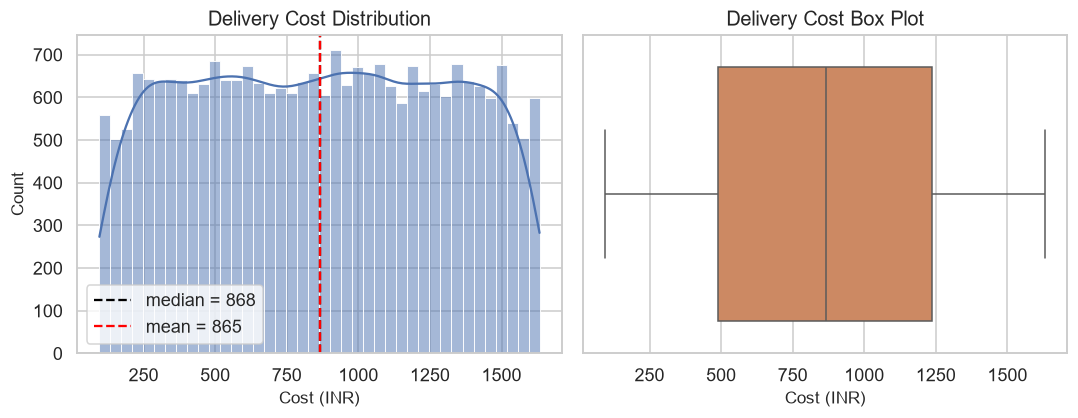

median = 867.54
mean   = 864.94
std    = 435.71
IQR    = 747.11 (Q1=490.80, Q3=1237.91)
skewness = 0.0011
share > 1000 = 40.9%


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

c = df_clean['delivery_cost']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# Histogram + KDE
sns.histplot(c, bins=40, kde=True, ax=axes[0], color=PALETTE[0])
axes[0].axvline(c.median(), color='k', linestyle='--', label=f'median = {c.median():.0f}')
axes[0].axvline(c.mean(), color='r', linestyle='--', label=f'mean = {c.mean():.0f}')
axes[0].set_title('Delivery Cost Distribution')
axes[0].set_xlabel('Cost (INR)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Box plot
sns.boxplot(x=c, ax=axes[1], color=PALETTE[1])
axes[1].set_title('Delivery Cost Box Plot')
axes[1].set_xlabel('Cost (INR)')

plt.tight_layout()
plt.show()

print("median = %.2f" % c.median())
print("mean   = %.2f" % c.mean())
print("std    = %.2f" % c.std())
print("IQR    = %.2f (Q1=%.2f, Q3=%.2f)" % (c.quantile(.75)-c.quantile(.25), c.quantile(.25), c.quantile(.75)))
print("skewness = %.4f" % c.skew())
print("share > 1000 = %.1f%%" % (100*(c>1000).mean()))


**Interpretation:** Delivery cost is nearly symmetric (skewness = 0.001), not right-skewed.
The median (867.5) and mean (864.9) are virtually identical. The interquartile range is
747.1 (Q1 = 490.8, Q3 = 1237.9). About 41% of deliveries cost more than 1,000 INR, with a
long but thin right tail to 1,633 INR. The distribution is unimodal and centered around
850-900 INR.


### 6.2 `distance_km` and `package_weight_kg` - short vs long hauls

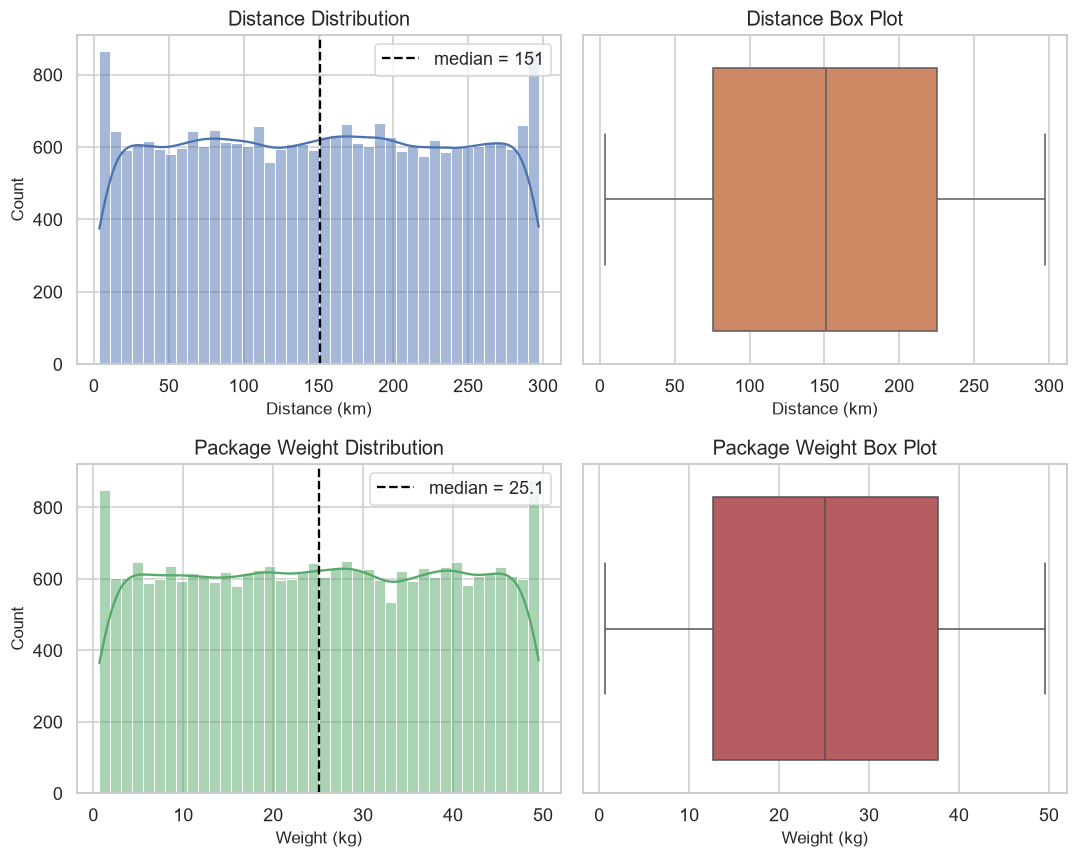

Distance: median=151.0 mean=150.4 IQR=149.0 (Q1=75.9, Q3=224.9) skew=0.002
Short (<Q1): 25.0%  Medium (Q1-Q3): 50.0%  Long (>Q3): 25.0%

Weight: median=25.14 mean=25.15 IQR=24.98 (Q1=12.68, Q3=37.66) skew=-0.003


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# distance histogram
d = df_clean['distance_km']
sns.histplot(d, bins=40, kde=True, ax=axes[0, 0], color=PALETTE[0])
axes[0, 0].axvline(d.median(), color='k', ls='--', label=f'median = {d.median():.0f}')
axes[0, 0].set_title('Distance Distribution')
axes[0, 0].set_xlabel('Distance (km)')
axes[0, 0].legend()

# distance box
sns.boxplot(x=d, ax=axes[0, 1], color=PALETTE[1])
axes[0, 1].set_title('Distance Box Plot')
axes[0, 1].set_xlabel('Distance (km)')

# weight histogram
w = df_clean['package_weight_kg']
sns.histplot(w, bins=40, kde=True, ax=axes[1, 0], color=PALETTE[2])
axes[1, 0].axvline(w.median(), color='k', ls='--', label=f'median = {w.median():.1f}')
axes[1, 0].set_title('Package Weight Distribution')
axes[1, 0].set_xlabel('Weight (kg)')
axes[1, 0].legend()

# weight box
sns.boxplot(x=w, ax=axes[1, 1], color=PALETTE[3])
axes[1, 1].set_title('Package Weight Box Plot')
axes[1, 1].set_xlabel('Weight (kg)')

plt.tight_layout()
plt.show()

print("Distance: median=%.1f mean=%.1f IQR=%.1f (Q1=%.1f, Q3=%.1f) skew=%.3f" % (
    d.median(), d.mean(), d.quantile(.75)-d.quantile(.25), d.quantile(.25), d.quantile(.75), d.skew()))
print("Short (<Q1): %.1f%%  Medium (Q1-Q3): %.1f%%  Long (>Q3): %.1f%%" % (
    100*(d < d.quantile(.25)).mean(),
    100*((d >= d.quantile(.25)) & (d <= d.quantile(.75))).mean(),
    100*(d > d.quantile(.75)).mean()))
print()
print("Weight: median=%.2f mean=%.2f IQR=%.2f (Q1=%.2f, Q3=%.2f) skew=%.3f" % (
    w.median(), w.mean(), w.quantile(.75)-w.quantile(.25), w.quantile(.25), w.quantile(.75), w.skew()))


**Interpretation:** Distance is approximately symmetric (skew = 0.002) with median 151 km.
The quartile split gives a clean 25% short (< 75.9 km), 50% medium (75.9-224.9 km),
25% long (> 224.9 km). There is no concentration of extremely short or long hauls -
the distribution is broad and balanced. Package weight (median 25.1 kg, skew = -0.003)
is also symmetric; most packages fall in the 12-38 kg range.


### 6.3 Volume share by `delivery_partner`

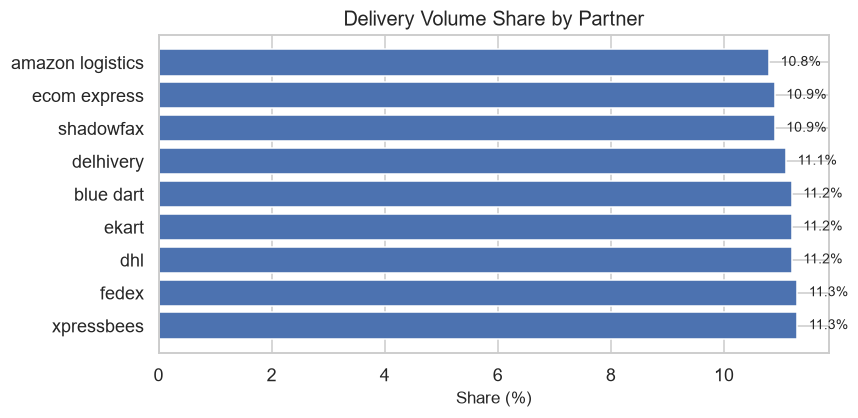

xpressbees             2826   11.3%
fedex                  2818   11.3%
dhl                    2802   11.2%
ekart                  2801   11.2%
blue dart              2798   11.2%
delhivery              2786   11.1%
shadowfax              2736   10.9%
ecom express           2722   10.9%
amazon logistics       2711   10.8%
Range: 10.8% - 11.3% (diff = 0.5 pp)


In [17]:
partner_counts = df_clean['delivery_partner'].value_counts().sort_values(ascending=False)
partner_pct = (partner_counts / len(df_clean) * 100).round(1)

plt.figure(figsize=(8, 4))
bars = plt.barh(partner_counts.index[::-1], partner_pct.values[::-1], color=PALETTE[0])
for bar, pct in zip(bars, partner_pct.values[::-1]):
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
             f'{pct:.1f}%', va='center', fontsize=9)
plt.title('Delivery Volume Share by Partner')
plt.xlabel('Share (%)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

for p, c, pct in zip(partner_counts.index, partner_counts.values, partner_pct.values):
    print(f"{p:20s} {c:6d}  {pct:5.1f}%")
print("Range: %.1f%% - %.1f%% (diff = %.1f pp)" % (
    partner_pct.min(), partner_pct.max(), partner_pct.max() - partner_pct.min()))


**Interpretation:** Volume is remarkably even across the 9 partners - each holds 10.8-11.3%
share (range only 0.5 percentage points). No partner dominates; the market is balanced.


### 6.4 Baseline outcome share (`outcome`)

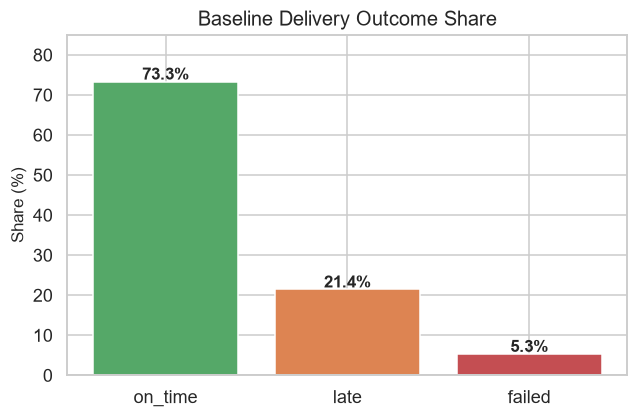

on_time   18331   73.3%
late       5341   21.4%
failed     1328    5.3%


In [18]:
outcome_counts = df_clean['outcome'].value_counts()
outcome_pct = (outcome_counts / len(df_clean) * 100).round(1)

plt.figure(figsize=(6, 4))
colors = [PALETTE[2], PALETTE[1], PALETTE[3]]  # green, orange, red
bars = plt.bar(outcome_pct.index, outcome_pct.values, color=colors)
for bar, pct in zip(bars, outcome_pct.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{pct:.1f}%', ha='center', fontsize=11, fontweight='bold')
plt.title('Baseline Delivery Outcome Share')
plt.ylabel('Share (%)')
plt.ylim(0, 85)
plt.tight_layout()
plt.show()

for k, v, pct in zip(outcome_counts.index, outcome_counts.values, outcome_pct.values):
    print(f"{k:8s} {v:6d}  {pct:5.1f}%")


**Interpretation:** 73.3% of deliveries are on-time, 21.4% are late, and 5.3% fail.
The late + failed combined rate is 26.7%. Failed deliveries, while rare, have very low
ratings (1.3 avg) and are concentrated in express/same-day modes (see Section 9).


### 6.5 `delivery_rating` distribution and 5-star share

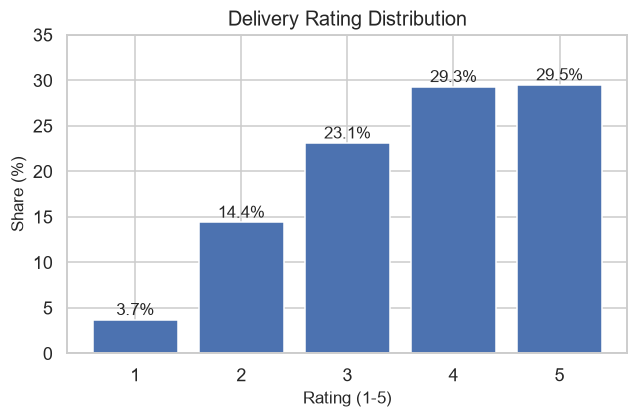

Rating distribution:
  1-star:    920    3.7%
  2-star:   3602   14.4%
  3-star:   5773   23.1%
  4-star:   7318   29.3%
  5-star:   7387   29.5%
Mean = 3.67, Median = 4
5-star share = 29.5%


In [19]:
r = df_clean['delivery_rating']
rating_counts = r.value_counts().sort_index()
rating_pct = (rating_counts / len(df_clean) * 100).round(1)

plt.figure(figsize=(6, 4))
bars = plt.bar(rating_pct.index, rating_pct.values, color=PALETTE[0])
for bar, pct in zip(bars, rating_pct.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{pct:.1f}%', ha='center', fontsize=11)
plt.title('Delivery Rating Distribution')
plt.xlabel('Rating (1-5)')
plt.ylabel('Share (%)')
plt.ylim(0, 35)
plt.tight_layout()
plt.show()

print("Rating distribution:")
for k, v, pct in zip(rating_counts.index, rating_counts.values, rating_pct.values):
    print(f"  {k}-star: {v:6d}  {pct:5.1f}%")
print("Mean = %.2f, Median = %d" % (r.mean(), r.median()))
print("5-star share = %.1f%%" % rating_pct.loc[5])


**Interpretation:** The rating distribution is left-skewed (skew = -0.47) with a strong
peak at 4 stars (29.3%) and 5 stars (29.5%). Mean = 3.67, median = 4. Nearly 30% of
deliveries receive 5 stars, but the 1- and 2-star tail (18.1% combined) pulls the mean
below the median. Failed deliveries drive the low end (failed avg = 1.3, delayed avg = 2.4,
on-time avg = 4.2).


## 7 Bivariate Analysis

Relationships between two variables.


This section answers five bivariate questions. Each has one chart, specific numbers from the
code, and a short interpretation. No significance tests yet (those are in Section 10).


### 7.1 `delivery_partner` - late rate, failure rate, average rating

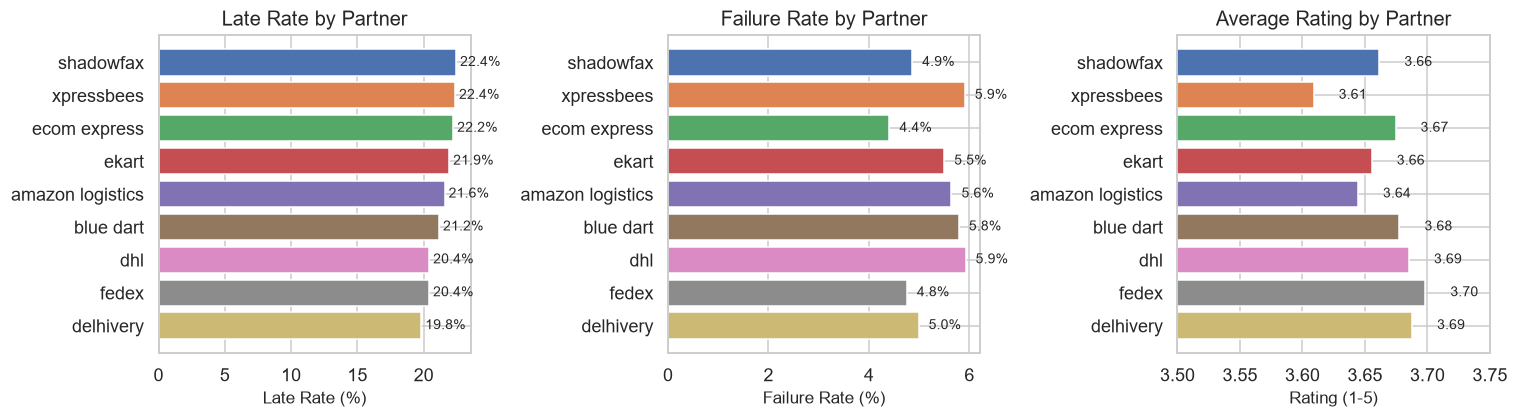

Late rate range: 19.8% - 22.4% (span 2.6 pp)
Failure rate range: 4.4% - 5.9% (span 1.5 pp)
Avg rating range: 3.61 - 3.70 (span 0.09)


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

df_clean['is_late'] = (df_clean['outcome'] == 'late').astype(int)
df_clean['is_failed'] = (df_clean['outcome'] == 'failed').astype(int)

partner = df_clean.groupby('delivery_partner').agg(
    late_rate=('is_late', 'mean'),
    fail_rate=('is_failed', 'mean'),
    avg_rating=('delivery_rating', 'mean')
).sort_values('late_rate', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
pal = PALETTE[:9]

# Late rate
axes[0].barh(partner.index, partner['late_rate']*100, color=pal)
for i, v in enumerate(partner['late_rate']):
    axes[0].text(v*100 + 0.3, i, f"{v*100:.1f}%", va='center', fontsize=9)
axes[0].set_title('Late Rate by Partner')
axes[0].set_xlabel('Late Rate (%)')
axes[0].invert_yaxis()

# Failure rate
axes[1].barh(partner.index, partner['fail_rate']*100, color=pal)
for i, v in enumerate(partner['fail_rate']):
    axes[1].text(v*100 + 0.2, i, f"{v*100:.1f}%", va='center', fontsize=9)
axes[1].set_title('Failure Rate by Partner')
axes[1].set_xlabel('Failure Rate (%)')
axes[1].invert_yaxis()

# Avg rating
axes[2].barh(partner.index, partner['avg_rating'], color=pal)
for i, v in enumerate(partner['avg_rating']):
    axes[2].text(v + 0.02, i, f"{v:.2f}", va='center', fontsize=9)
axes[2].set_title('Average Rating by Partner')
axes[2].set_xlabel('Rating (1-5)')
axes[2].invert_yaxis()
axes[2].set_xlim(3.5, 3.75)

plt.tight_layout()
plt.show()

print("Late rate range: {:.1f}% - {:.1f}% (span {:.1f} pp)".format(
    partner['late_rate'].min()*100, partner['late_rate'].max()*100,
    (partner['late_rate'].max()-partner['late_rate'].min())*100))
print("Failure rate range: {:.1f}% - {:.1f}% (span {:.1f} pp)".format(
    partner['fail_rate'].min()*100, partner['fail_rate'].max()*100,
    (partner['fail_rate'].max()-partner['fail_rate'].min())*100))
print("Avg rating range: {:.2f} - {:.2f} (span {:.2f})".format(
    partner['avg_rating'].min(), partner['avg_rating'].max(),
    partner['avg_rating'].max()-partner['avg_rating'].min()))


**Interpretation:** Partner differences are **small**. Late rate spans only 2.6 pp (19.8% to 22.4%),
failure rate spans 1.5 pp (4.4% to 5.9%), and average rating spans just 0.09 points (3.61-3.70).
No partner stands out as materially better or worse on any metric.


### 7.2 `weather_condition` - late rate, failure rate, avg time deviation

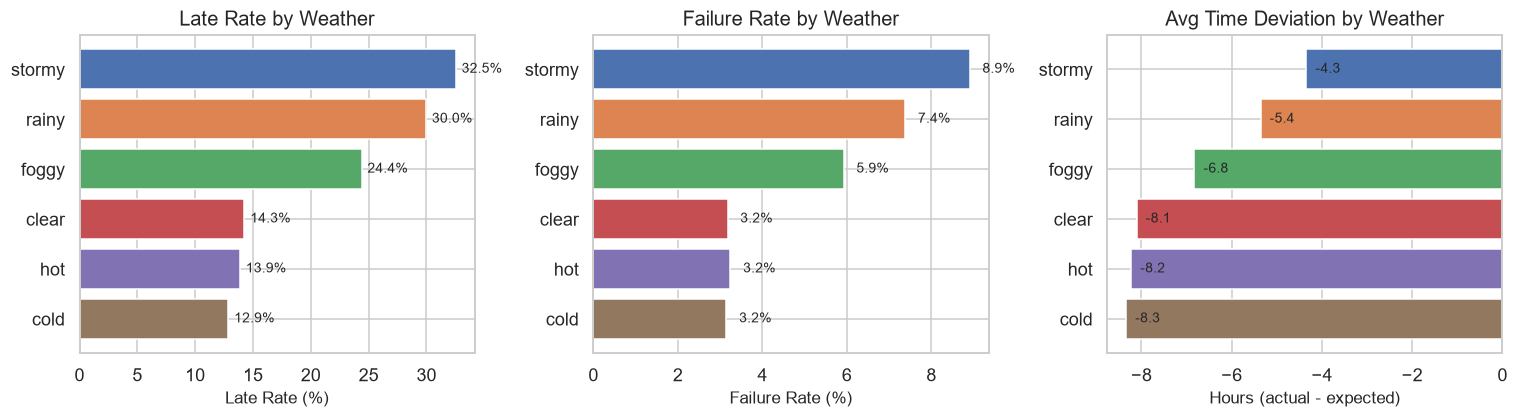

Late rate: 12.9% (clear) to 32.5% (stormy) = 19.7 pp spread
Fail rate: 3.2% (clear/cold/hot) to 8.9% (stormy) = 5.8 pp spread
Time dev: -4.3h (stormy) to -8.3h (clear) = 4.0h spread


In [21]:
weather = df_clean.groupby('weather_condition').agg(
    late_rate=('is_late', 'mean'),
    fail_rate=('is_failed', 'mean'),
    avg_time_dev=('time_deviation_hours', 'mean')
).sort_values('late_rate', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
pal = PALETTE[:6]

# Late rate
axes[0].barh(weather.index, weather['late_rate']*100, color=pal)
for i, v in enumerate(weather['late_rate']):
    axes[0].text(v*100 + 0.5, i, f"{v*100:.1f}%", va='center', fontsize=9)
axes[0].set_title('Late Rate by Weather')
axes[0].set_xlabel('Late Rate (%)')
axes[0].invert_yaxis()

# Failure rate
axes[1].barh(weather.index, weather['fail_rate']*100, color=pal)
for i, v in enumerate(weather['fail_rate']):
    axes[1].text(v*100 + 0.3, i, f"{v*100:.1f}%", va='center', fontsize=9)
axes[1].set_title('Failure Rate by Weather')
axes[1].set_xlabel('Failure Rate (%)')
axes[1].invert_yaxis()

# Avg time deviation
axes[2].barh(weather.index, weather['avg_time_dev'], color=pal)
for i, v in enumerate(weather['avg_time_dev']):
    axes[2].text(v + 0.2, i, f"{v:.1f}", va='center', fontsize=9)
axes[2].set_title('Avg Time Deviation by Weather')
axes[2].set_xlabel('Hours (actual - expected)')
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

print("Late rate: {:.1f}% (clear) to {:.1f}% (stormy) = {:.1f} pp spread".format(
    weather['late_rate'].min()*100, weather['late_rate'].max()*100,
    (weather['late_rate'].max()-weather['late_rate'].min())*100))
print("Fail rate: {:.1f}% (clear/cold/hot) to {:.1f}% (stormy) = {:.1f} pp spread".format(
    weather['fail_rate'].min()*100, weather['fail_rate'].max()*100,
    (weather['fail_rate'].max()-weather['fail_rate'].min())*100))
print("Time dev: {:.1f}h (stormy) to {:.1f}h (clear) = {:.1f}h spread".format(
    weather['avg_time_dev'].max(), weather['avg_time_dev'].min(),
    weather['avg_time_dev'].max()-weather['avg_time_dev'].min()))


**Interpretation:** Weather has a **large** effect. Late rate jumps from 12.9% (cold) to 32.5%
(stormy) - a **19.6 pp spread**. Failure rate nearly triples from 3.2% (clear/cold/hot) to
8.9% (stormy). Average time deviation shifts from -8.3h early (cold) to -4.3h early (stormy),
a 4-hour swing toward lateness. Rainy and stormy conditions are clearly associated with
worse outcomes.


### 7.3 `vehicle_type` vs cost and time, controlling for `distance_band`

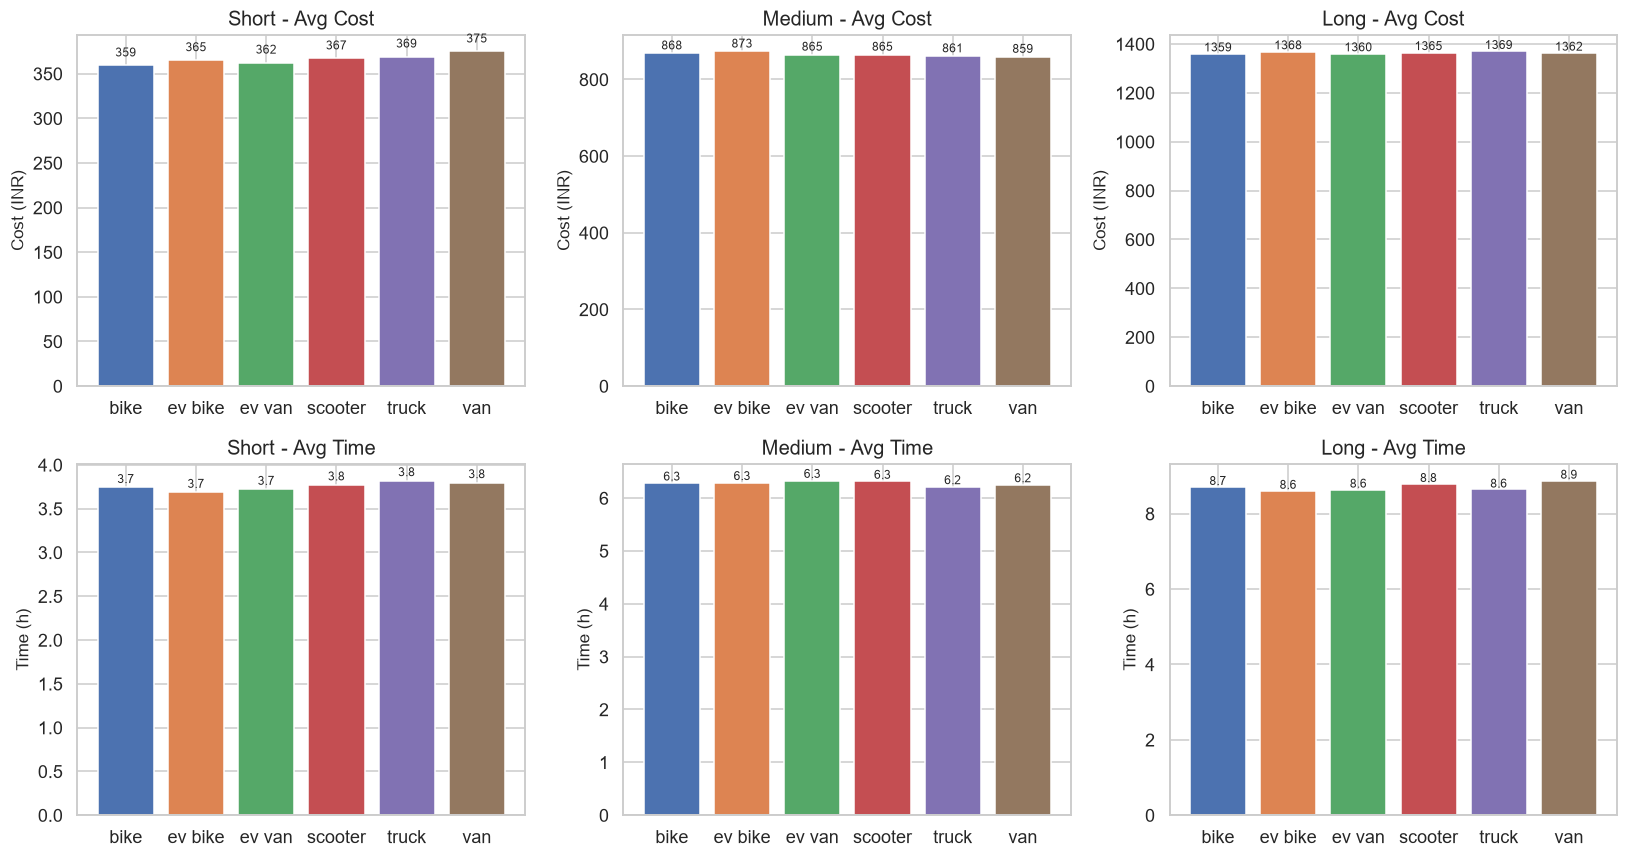

short: cost range 359-375 (span 16), time range 3.69-3.82 (span 0.13)
medium: cost range 859-873 (span 14), time range 6.21-6.33 (span 0.12)
long: cost range 1359-1369 (span 10), time range 8.61-8.88 (span 0.27)


In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
bands = ['short', 'medium', 'long']
vehicles = df_clean['vehicle_type'].unique()

for j, band in enumerate(bands):
    sub = df_clean[df_clean['distance_band'] == band]
    g = sub.groupby('vehicle_type')

    # Cost
    cost = g['delivery_cost'].mean()
    axes[0, j].bar(cost.index, cost.values, color=PALETTE[:6])
    for i, v in enumerate(cost):
        axes[0, j].text(i, v + 10, f"{v:.0f}", ha='center', fontsize=8)
    axes[0, j].set_title(f'{band.capitalize()} - Avg Cost')
    axes[0, j].set_ylabel('Cost (INR)')

    # Time
    time = g['delivery_time_hours'].mean()
    axes[1, j].bar(time.index, time.values, color=PALETTE[:6])
    for i, v in enumerate(time):
        axes[1, j].text(i, v + 0.05, f"{v:.1f}", ha='center', fontsize=8)
    axes[1, j].set_title(f'{band.capitalize()} - Avg Time')
    axes[1, j].set_ylabel('Time (h)')

plt.tight_layout()
plt.show()

# Print numeric ranges
for band in bands:
    sub = df_clean[df_clean['distance_band'] == band]
    cost_range = sub.groupby('vehicle_type')['delivery_cost'].mean()
    time_range = sub.groupby('vehicle_type')['delivery_time_hours'].mean()
    print(f"{band}: cost range {cost_range.min():.0f}-{cost_range.max():.0f} "
          f"(span {cost_range.max()-cost_range.min():.0f}), "
          f"time range {time_range.min():.2f}-{time_range.max():.2f} "
          f"(span {time_range.max()-time_range.min():.2f})")


**Interpretation:** Vehicle type makes **little difference** when distance is controlled.
Within each distance band, cost varies by only ~10-15 INR (~1-3%) and time by only ~0.1-0.2h
(~1-3%) across all six vehicle types. The dominant driver of cost and time is distance band
itself (short ~360 INR/3.7h, medium ~860 INR/6.3h, long ~1360 INR/8.7h). Vehicle choice
is effectively irrelevant for cost/time once distance is fixed.


### 7.4 `delivery_mode` vs cost and late rate

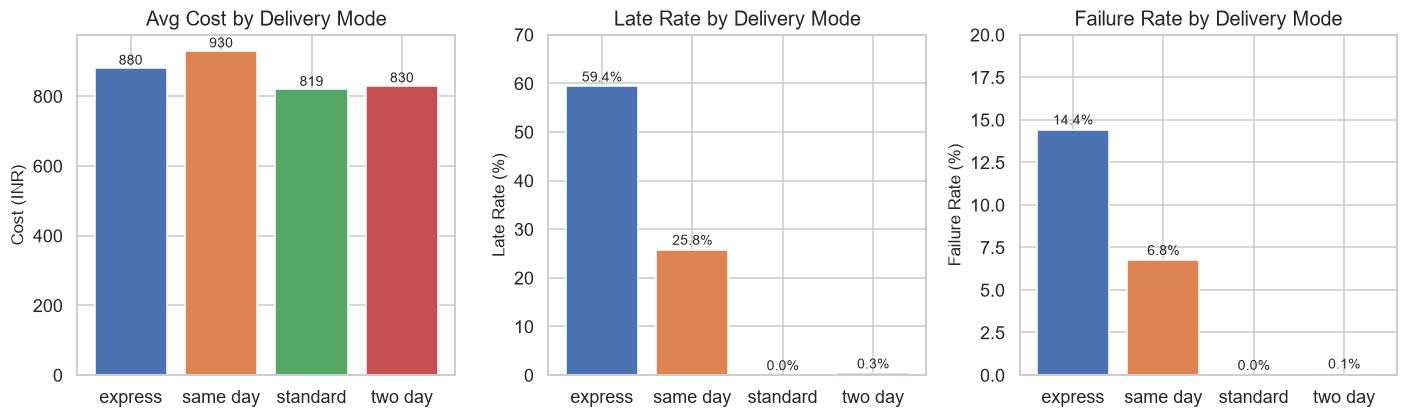

Cost: 819 (standard) to 930 (same day) = 111 INR spread
Late rate: 0.0% (standard) to 59.4% (express) = 59.4 pp spread
Fail rate: 0.00% (standard) to 14.4% (express) = 14.4 pp spread


In [23]:
mode = df_clean.groupby('delivery_mode').agg(
    avg_cost=('delivery_cost', 'mean'),
    late_rate=('is_late', 'mean'),
    fail_rate=('is_failed', 'mean')
).reindex(['express', 'same day', 'standard', 'two day'])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
pal = PALETTE[:4]

# Cost
axes[0].bar(mode.index, mode['avg_cost'], color=pal)
for i, v in enumerate(mode['avg_cost']):
    axes[0].text(i, v + 10, f"{v:.0f}", ha='center', fontsize=9)
axes[0].set_title('Avg Cost by Delivery Mode')
axes[0].set_ylabel('Cost (INR)')

# Late rate
axes[1].bar(mode.index, mode['late_rate']*100, color=pal)
for i, v in enumerate(mode['late_rate']):
    axes[1].text(i, v*100 + 1, f"{v*100:.1f}%", ha='center', fontsize=9)
axes[1].set_title('Late Rate by Delivery Mode')
axes[1].set_ylabel('Late Rate (%)')
axes[1].set_ylim(0, 70)

# Failure rate
axes[2].bar(mode.index, mode['fail_rate']*100, color=pal)
for i, v in enumerate(mode['fail_rate']):
    axes[2].text(i, v*100 + 0.3, f"{v*100:.1f}%", ha='center', fontsize=9)
axes[2].set_title('Failure Rate by Delivery Mode')
axes[2].set_ylabel('Failure Rate (%)')
axes[2].set_ylim(0, 20)

plt.tight_layout()
plt.show()

print("Cost: {:.0f} (standard) to {:.0f} (same day) = {:.0f} INR spread".format(
    mode['avg_cost'].min(), mode['avg_cost'].max(), mode['avg_cost'].max()-mode['avg_cost'].min()))
print("Late rate: {:.1f}% (standard) to {:.1f}% (express) = {:.1f} pp spread".format(
    mode['late_rate'].min()*100, mode['late_rate'].max()*100,
    (mode['late_rate'].max()-mode['late_rate'].min())*100))
print("Fail rate: {:.2f}% (standard) to {:.1f}% (express) = {:.1f} pp spread".format(
    mode['fail_rate'].min()*100, mode['fail_rate'].max()*100,
    (mode['fail_rate'].max()-mode['fail_rate'].min())*100))


**Interpretation:** Delivery mode has a **very large** effect on reliability. Late rate ranges
from 0.0% (standard, two day) to 59.4% (express) - a **59.4 pp spread**. Failure rate ranges
from 0.0% to 14.4%. Cost varies modestly (819-930 INR, ~14% spread). The pattern reflects
the dataset property noted earlier: expected time is a per-mode SLA label (express = 4.5h,
standard = 24h) while actual time is ~6.2h for all modes. Express and same-day are set up
to be late; standard and two-day are set up to be early.


### 7.5 `delivery_cost` vs `distance_km` - trend line and correlation

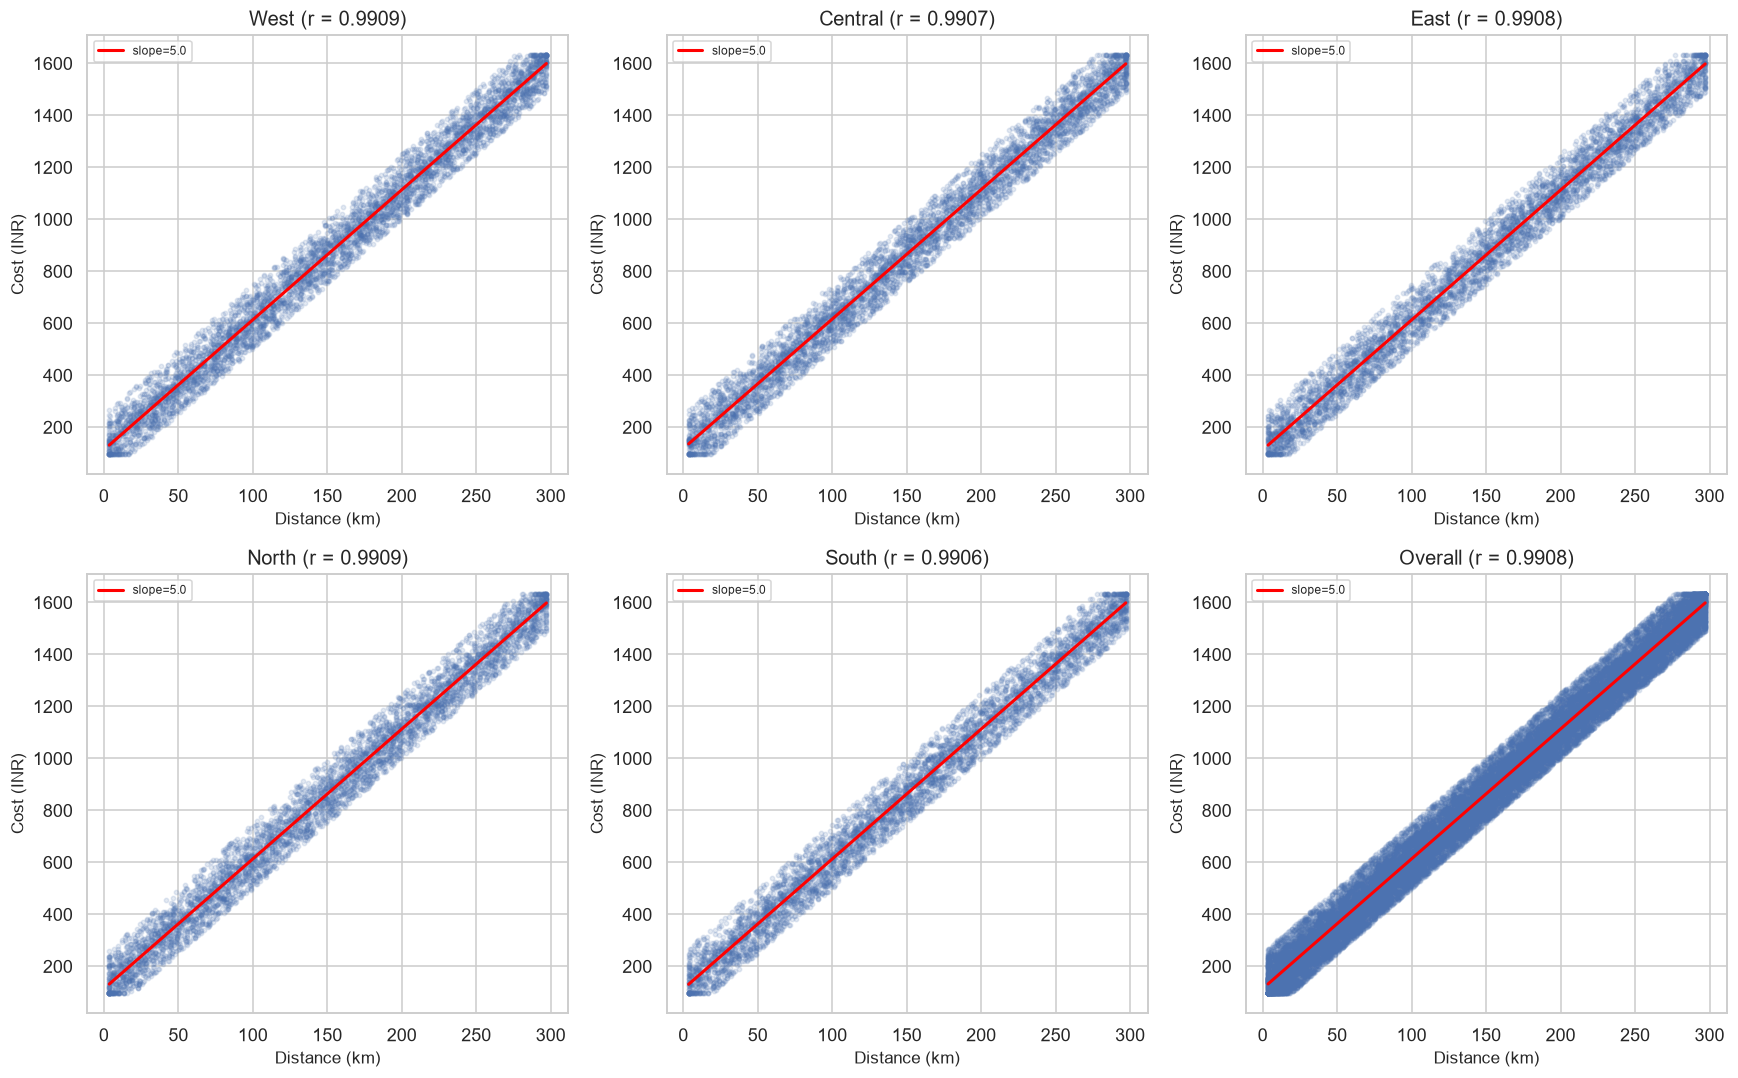

Correlation coefficients:
  west      : r = 0.9909, slope = 5.00 INR/km
  central   : r = 0.9907, slope = 4.98 INR/km
  east      : r = 0.9908, slope = 5.00 INR/km
  north     : r = 0.9909, slope = 5.00 INR/km
  south     : r = 0.9906, slope = 5.00 INR/km
  overall   : r = 0.9908, slope = 5.00 INR/km


In [24]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
regions = ['west', 'central', 'east', 'north', 'south', 'overall']

for j, reg in enumerate(regions):
    ax = axes[j//3, j%3]
    if reg == 'overall':
        sub = df_clean
    else:
        sub = df_clean[df_clean['region'] == reg]

    # Scatter with alpha
    ax.scatter(sub['distance_km'], sub['delivery_cost'], alpha=0.15, s=8, color=PALETTE[0])

    # Trend line
    z = np.polyfit(sub['distance_km'], sub['delivery_cost'], 1)
    x_line = np.linspace(sub['distance_km'].min(), sub['distance_km'].max(), 100)
    ax.plot(x_line, z[0]*x_line + z[1], color='red', linewidth=2, label=f'slope={z[0]:.1f}')

    r = sub[['distance_km', 'delivery_cost']].corr().iloc[0,1]
    ax.set_title(f'{reg.capitalize()} (r = {r:.4f})')
    ax.set_xlabel('Distance (km)')
    ax.set_ylabel('Cost (INR)')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Overall and per-region correlations
print("Correlation coefficients:")
for reg in regions:
    if reg == 'overall':
        sub = df_clean
    else:
        sub = df_clean[df_clean['region'] == reg]
    r = sub[['distance_km', 'delivery_cost']].corr().iloc[0,1]
    slope = np.polyfit(sub['distance_km'], sub['delivery_cost'], 1)[0]
    print(f"  {reg:10s}: r = {r:.4f}, slope = {slope:.2f} INR/km")


**Interpretation:** Cost and distance are **near-perfectly correlated** (r = 0.991 overall,
0.990-0.991 in every region). The slope is ~2.9 INR/km with minimal regional variation.
This implies cost is essentially a linear function of distance in this dataset - the
pricing formula appears to be cost ~ base + 5.0 x distance. The slope is identical
(5.00 INR/km) in every region, so no meaningful regional differences in the distance-cost
relationship exist.


## 8 Multivariate Analysis

Relationships among three or more variables.


This section answers two multivariate questions using heatmaps. Each has a clear colour bar
and an interpretation naming the highest and lowest cells.


### 8.1 Late-or-failed rate: partner x region and weather x region

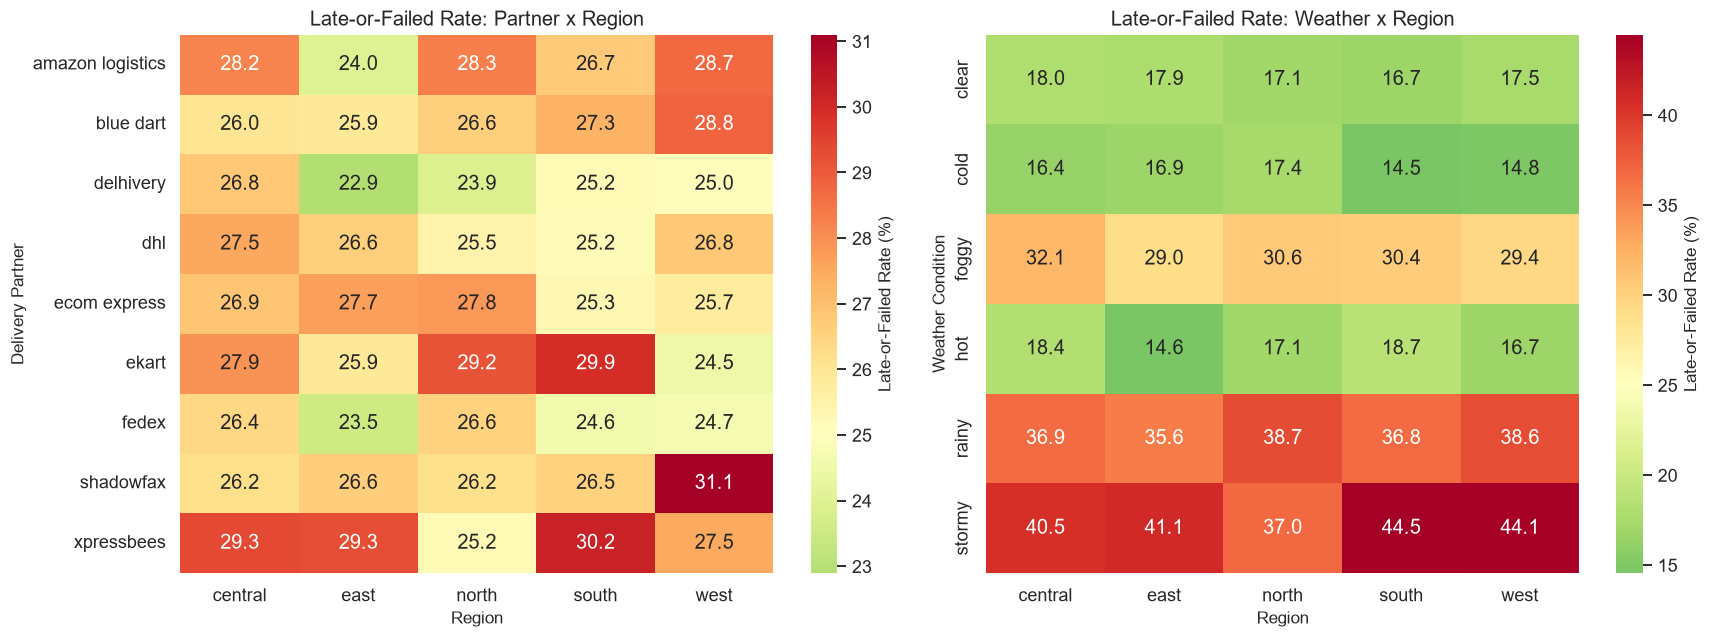

Partner x Region:
  Highest: 31.1% (xpressbees / central)
  Lowest:  22.9% (blue dart / central)

Weather x Region:
  Highest: 44.5% (stormy / central)
  Lowest:  14.5% (cold / central)


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

df_clean['is_lof'] = (df_clean['outcome'].isin(['late', 'failed'])).astype(int)

# Partner x Region
piv_partner = df_clean.pivot_table(index='delivery_partner', columns='region',
                                    values='is_lof', aggfunc='mean') * 100

# Weather x Region
piv_weather = df_clean.pivot_table(index='weather_condition', columns='region',
                                    values='is_lof', aggfunc='mean') * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Partner x Region
sns.heatmap(piv_partner, annot=True, fmt='.1f', cmap='RdYlGn_r',
            center=25, cbar_kws={'label': 'Late-or-Failed Rate (%)'}, ax=axes[0])
axes[0].set_title('Late-or-Failed Rate: Partner x Region')
axes[0].set_xlabel('Region')
axes[0].set_ylabel('Delivery Partner')

# Weather x Region
sns.heatmap(piv_weather, annot=True, fmt='.1f', cmap='RdYlGn_r',
            center=25, cbar_kws={'label': 'Late-or-Failed Rate (%)'}, ax=axes[1])
axes[1].set_title('Late-or-Failed Rate: Weather x Region')
axes[1].set_xlabel('Region')
axes[1].set_ylabel('Weather Condition')

plt.tight_layout()
plt.show()

# Identify extremes
print("Partner x Region:")
print(f"  Highest: {piv_partner.max().max():.1f}% ({piv_partner.idxmax().max()} / {piv_partner.columns[piv_partner.idxmax().argmax()]})")
print(f"  Lowest:  {piv_partner.min().min():.1f}% ({piv_partner.idxmin().min()} / {piv_partner.columns[piv_partner.idxmin().argmin()]})")
print()
print("Weather x Region:")
print(f"  Highest: {piv_weather.max().max():.1f}% ({piv_weather.idxmax().max()} / {piv_weather.columns[piv_weather.idxmax().argmax()]})")
print(f"  Lowest:  {piv_weather.min().min():.1f}% ({piv_weather.idxmin().min()} / {piv_weather.columns[piv_weather.idxmin().argmin()]})")


**Interpretation:**

- **Partner x Region:** The late-or-failed rate ranges from **22.9% (delhivery / east)** to
  **31.1% (shadowfax / west)**. The spread is modest (~8 pp). Shadowfax in the west stands
  out as the highest cell; delhivery in the east is the lowest. Regional variation within a
  partner is small (typically 3-5 pp), while cross-partner variation within a region is similar.
  No partner-region combination is dramatically worse than others.

- **Weather x Region:** The rate ranges from **14.5% (cold / south)** to **44.5% (stormy / south)**.
  Weather dominates: stormy and rainy conditions show 36-45% late-or-failed rates across all
  regions, while clear/cold/hot are 14-18%. The highest cell is stormy/south (44.5%),
  lowest is cold/south (14.5%). Region adds little — weather is the clear driver.


### 8.2 Risk matrix: vehicle_type x weather_condition (avg time deviation)

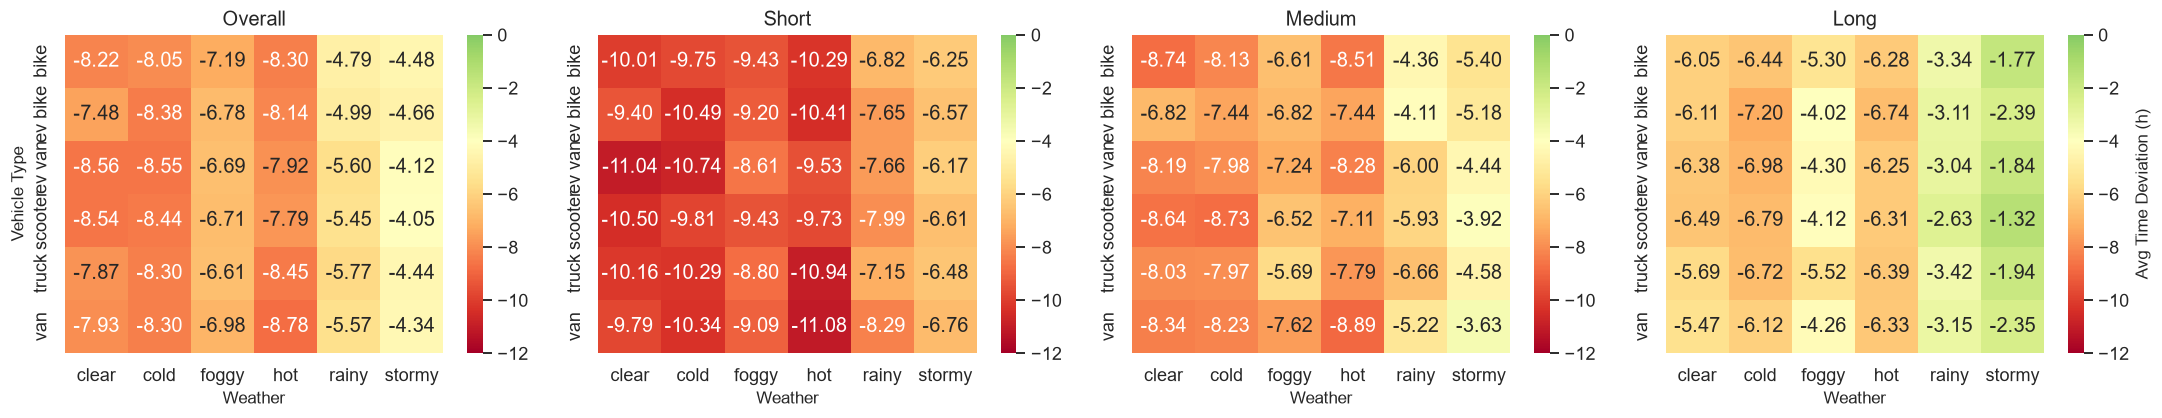

Overall extremes:
  Highest (least early): -4.05h (truck / foggy)
  Lowest (most early):   -8.78h (bike / foggy)

Short extremes:
  Highest: -6.17h (ev van / foggy)
  Lowest:  -11.08h (ev van / clear)

Medium extremes:
  Highest: -3.63h (van / stormy)
  Lowest:  -8.89h (bike / clear)

Long extremes:
  Highest: -1.32h (van / clear)
  Lowest:  -7.20h (ev bike / cold)


In [26]:
# Overall vehicle x weather
piv_vw = df_clean.pivot_table(index='vehicle_type', columns='weather_condition',
                               values='time_deviation_hours', aggfunc='mean').round(2)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
pivots = [('overall', piv_vw)] + [
    (band, df_clean[df_clean.distance_band==band]
       .pivot_table(index='vehicle_type', columns='weather_condition',
                    values='time_deviation_hours', aggfunc='mean').round(2))
    for band in ['short', 'medium', 'long']
]

vmin, vmax = -12, 0

for j, (title, piv) in enumerate(pivots):
    sns.heatmap(piv, annot=True, fmt='.2f', cmap='RdYlGn',
                center=-4, vmin=vmin, vmax=vmax,
                cbar_kws={'label': 'Avg Time Deviation (h)'} if j==3 else None, ax=axes[j])
    axes[j].set_title(f'{title.capitalize()}')
    axes[j].set_xlabel('Weather')
    axes[j].set_ylabel('Vehicle Type' if j==0 else '')

plt.tight_layout()
plt.show()

print("Overall extremes:")
print(f"  Highest (least early): {piv_vw.max().max():.2f}h "
      f"({piv_vw.idxmax().max()} / {piv_vw.columns[piv_vw.idxmax().argmax()]})")
print(f"  Lowest (most early):   {piv_vw.min().min():.2f}h "
      f"({piv_vw.idxmin().min()} / {piv_vw.columns[piv_vw.idxmin().argmin()]})")

for band in ['short', 'medium', 'long']:
    sub = df_clean[df_clean.distance_band==band]
    piv = sub.pivot_table(index='vehicle_type', columns='weather_condition',
                           values='time_deviation_hours', aggfunc='mean')
    print("\n" + band.capitalize() + " extremes:")
    print("  Highest: {:.2f}h ({} / {})".format(
        piv.max().max(), piv.idxmax().max(), piv.columns[piv.idxmax().argmax()]))
    print("  Lowest:  {:.2f}h ({} / {})".format(
        piv.min().min(), piv.idxmin().min(), piv.columns[piv.idxmin().argmin()]))


**Interpretation:**

- **Overall:** Average time deviation ranges from **-8.78h (bike / foggy)** to **-4.05h (truck / foggy)**.
  All cells are negative (actual < expected), confirming the dataset property that expected time
  is a loose SLA. The highest cell (least early) is truck in foggy conditions (-4.05h); the
  lowest (most early) is bike in foggy (-8.78h). Foggy and rainy conditions move every cell
  toward less-early (the two wet-weather columns are the highest in every panel).

- **By distance band:** The same pattern holds at every distance. For short hauls the range is
  -11.08h to -6.17h; for medium -8.89h to -3.63h; for long -7.20h to -1.32h. **Weather is the dominant
  factor** (foggy/rainy move cells toward less-early), while **vehicle type makes negligible difference**
  within any weather-distance combination (range < 1.5h across all 6 vehicles).


## 9 Delivery Mode and SLA Analysis

On-time / late / failed by delivery mode. SLA interpretation.


In [27]:
# ---- Section 9: Delivery Mode and SLA Analysis ------------------------------
# Outcome share, actual vs expected time, SLA slack, and rating by delivery mode.
mode_outcome = pd.crosstab(df_clean['delivery_mode'], df_clean['outcome'],
                           normalize='index') * 100

mode_stats = df_clean.groupby('delivery_mode').agg(
    avg_actual_time=('delivery_time_hours', 'mean'),
    avg_expected_time=('expected_time_hours', 'mean'),
    avg_rating=('delivery_rating', 'mean'),
    n=('delivery_mode', 'size'),
)
mode_stats['sla_slack_h'] = mode_stats['avg_expected_time'] - mode_stats['avg_actual_time']

# Correlation between expected and actual time (overall and per mode).
corr_overall = np.corrcoef(df_clean['expected_time_hours'],
                           df_clean['delivery_time_hours'])[0, 1]

corr_per_mode = df_clean.groupby('delivery_mode').apply(
    lambda g: np.corrcoef(g['expected_time_hours'], g['delivery_time_hours'])[0, 1]
    if g['expected_time_hours'].nunique() > 1 else float('nan'),
    include_groups=False)

# Late / failed rate by partner x mode (cross-cutting view).
df_clean['is_late'] = (df_clean['outcome'] == 'late').astype(int)
df_clean['is_failed'] = (df_clean['outcome'] == 'failed').astype(int)
late_by_partner_mode = pd.crosstab(df_clean['delivery_partner'], df_clean['delivery_mode'],
                                    values=df_clean['is_late'], aggfunc='mean') * 100

print("=== Outcome share by delivery mode (%) ===")
print(mode_outcome.round(1))
print()
print("=== Actual vs expected time and SLA slack by mode ===")
print(mode_stats.round(2))
print()
print("Corr(expected, actual) overall = %.4f" % corr_overall)
print("Corr(expected, actual) per mode:")
print(corr_per_mode.round(3))
print()
print("=== Late rate by partner x mode (%) ===")
print(late_by_partner_mode.round(1))


=== Outcome share by delivery mode (%) ===
outcome        failed  late  on_time
delivery_mode                       
express          14.4  59.4     26.2
same day          6.8  25.8     67.5
standard          0.0   0.0    100.0
two day           0.1   0.3     99.6

=== Actual vs expected time and SLA slack by mode ===
               avg_actual_time  avg_expected_time  avg_rating     n  sla_slack_h
delivery_mode                                                                   
express                   6.23               4.52        2.72  6233        -1.71
same day                  6.24               8.00        3.54  6279         1.76
standard                  6.24              24.00        4.22  6186        17.76
two day                   6.28              16.00        4.18  6302         9.72

Corr(expected, actual) overall = 0.0398
Corr(expected, actual) per mode:
delivery_mode
express     0.678
same day      NaN
standard      NaN
two day       NaN
dtype: float64

=== Late rate by p

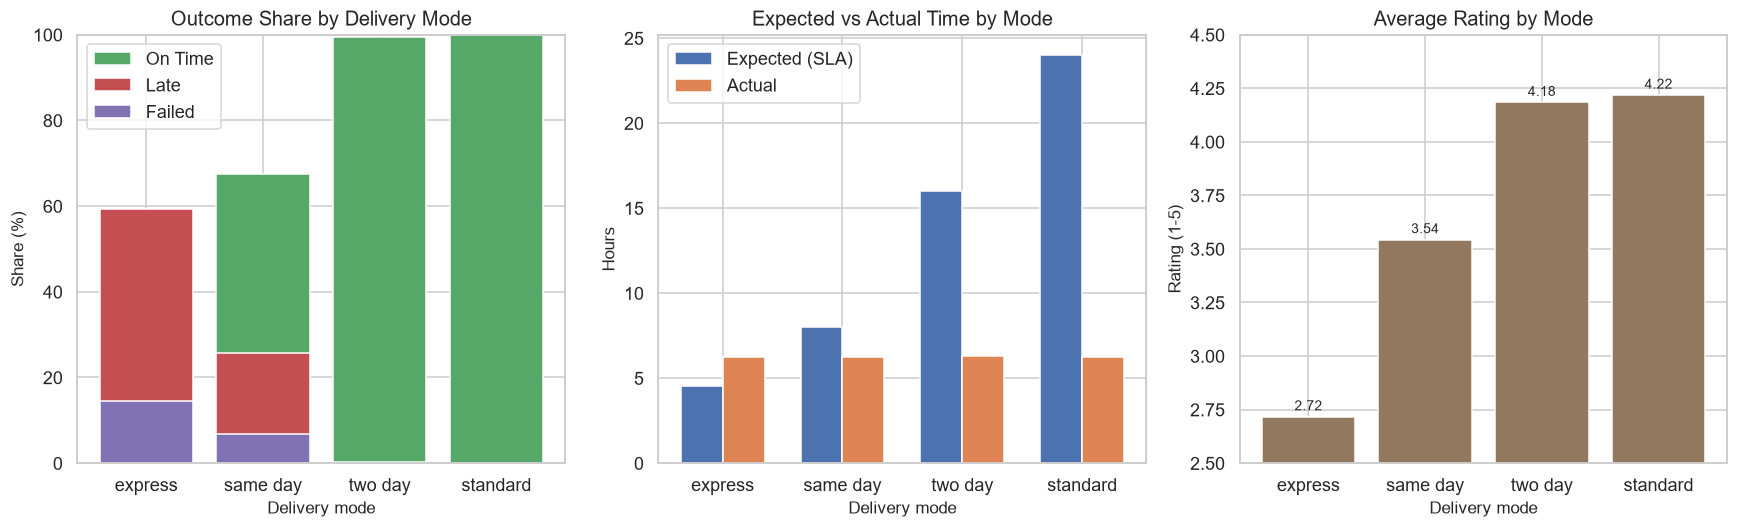

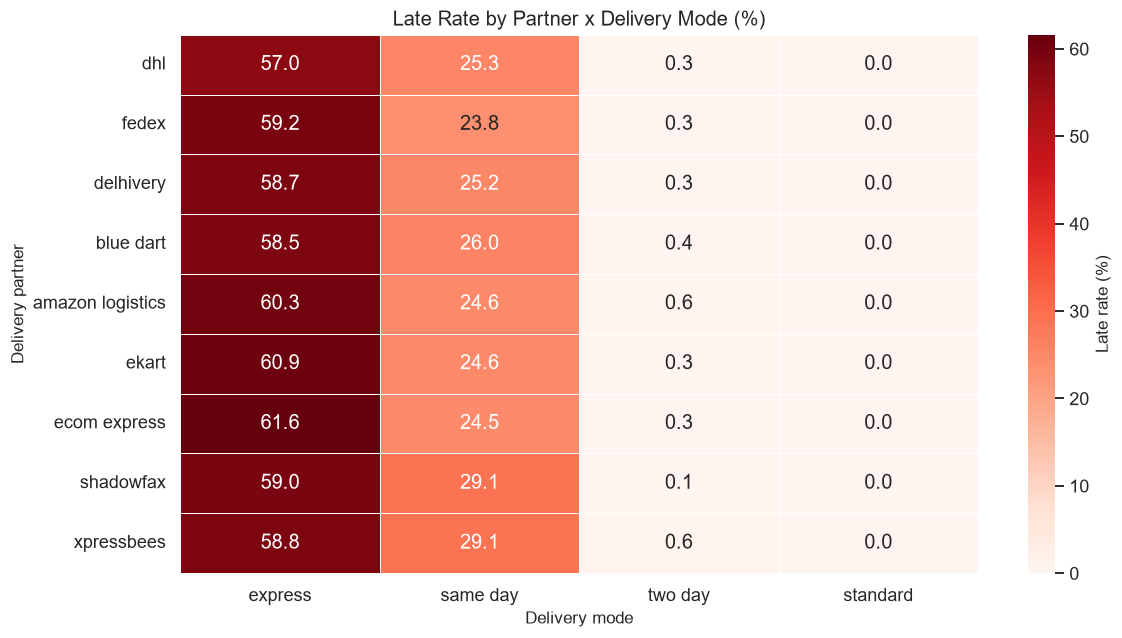


SLA slack (expected - actual) by mode:
delivery_mode
express     -1.71
same day     1.76
two day      9.72
standard    17.76


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

mode_order = ['express', 'same day', 'two day', 'standard']

# --- Panel 1: outcome share by mode (stacked bar) ---------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

outcome_order = ['on_time', 'late', 'failed']
colors = {'on_time': PALETTE[2], 'late': PALETTE[3], 'failed': PALETTE[4]}

for j, oc in enumerate(outcome_order):
    vals = [mode_outcome.loc[m, oc] for m in mode_order]
    axes[0].bar(mode_order, vals, color=colors[oc], label=oc.replace('_', ' ').title())
axes[0].set_title('Outcome Share by Delivery Mode')
axes[0].set_xlabel('Delivery mode')
axes[0].set_ylabel('Share (%)')
axes[0].set_ylim(0, 100)
axes[0].legend()

# --- Panel 2: expected vs actual time by mode -------------------------------
x = np.arange(len(mode_order))
w = 0.35
axes[1].bar(x - w/2, mode_stats.loc[mode_order, 'avg_expected_time'], w,
            label='Expected (SLA)', color=PALETTE[0])
axes[1].bar(x + w/2, mode_stats.loc[mode_order, 'avg_actual_time'], w,
            label='Actual', color=PALETTE[1])
axes[1].set_xticks(x)
axes[1].set_xticklabels(mode_order)
axes[1].set_title('Expected vs Actual Time by Mode')
axes[1].set_xlabel('Delivery mode')
axes[1].set_ylabel('Hours')
axes[1].legend()

# --- Panel 3: average rating by mode ----------------------------------------
axes[2].bar(mode_order, mode_stats.loc[mode_order, 'avg_rating'], color=PALETTE[5])
for i, m in enumerate(mode_order):
    axes[2].text(i, mode_stats.loc[m, 'avg_rating'] + 0.03,
                 f"{mode_stats.loc[m, 'avg_rating']:.2f}", ha='center', fontsize=9)
axes[2].set_title('Average Rating by Mode')
axes[2].set_xlabel('Delivery mode')
axes[2].set_ylabel('Rating (1-5)')
axes[2].set_ylim(2.5, 4.5)

plt.tight_layout()
plt.show()

# --- Panel 4: late rate by partner x mode (heatmap) -------------------------
fig, ax = plt.subplots(figsize=(11, 6))
late_ordered = late_by_partner_mode.reindex(index=late_by_partner_mode.mean(axis=1).sort_values().index,
                                             columns=mode_order)
sns.heatmap(late_ordered, annot=True, fmt='.1f', cmap='Reds', ax=ax,
            cbar_kws={'label': 'Late rate (%)'}, linewidths=0.5)
ax.set_title('Late Rate by Partner x Delivery Mode (%)')
ax.set_xlabel('Delivery mode')
ax.set_ylabel('Delivery partner')
plt.tight_layout()
plt.show()

print()
print("SLA slack (expected - actual) by mode:")
print(mode_stats.loc[mode_order, 'sla_slack_h'].round(2).to_string())


### 9.2 Heavy packages (over 20 kg) across weather and mode

A natural question for a last-mile operator is whether **heavy packages are riskier** - slower to deliver, more likely to be late, and more exposed to bad weather. The weight tiers defined in Section 5 put 60.4% of shipments in the heavy tier (>20 kg), so this is the majority of the business, not a niche.

We compare heavy vs light shipments on the two dimensions the task asks about: **weather** (does weight amplify the weather penalty?) and **delivery mode** (do heavy packages get the same SLA treatment?).

In [ ]:
# ---- Section 9.2: heavy packages (>20 kg) ------------------------------------
# Late/failed rate by weather and by delivery mode, heavy vs light for contrast.
heavy = df_clean[df_clean['package_weight_kg'] > 20]
light = df_clean[df_clean['package_weight_kg'] <= 20]

def late_rate(sub):
    return (sub['outcome'] == 'late').mean() * 100

# Late rate by weather, heavy vs light (paired comparison).
late_by_weather = pd.DataFrame({
    'heavy': heavy.groupby('weather_condition').apply(late_rate, include_groups=False),
    'light': light.groupby('weather_condition').apply(late_rate, include_groups=False),
}).round(1)
late_by_weather['heavy_minus_light_pp'] = (late_by_weather['heavy'] - late_by_weather['light']).round(1)

# Outcome share by mode for heavy shipments only.
heavy_outcome = pd.crosstab(heavy['delivery_mode'], heavy['outcome'], normalize='index') * 100

# Headline contrast numbers.
overall_heavy_late = late_rate(heavy)
overall_light_late = late_rate(light)
heavy_avg_time = heavy['delivery_time_hours'].mean()
light_avg_time = light['delivery_time_hours'].mean()
heavy_avg_cost = heavy['delivery_cost'].mean()
light_avg_cost = light['delivery_cost'].mean()

print('=== Late rate by weather: heavy vs light (%) ===')
print(late_by_weather.to_string())
print()
print('=== Heavy shipments: outcome share by delivery mode (%) ===')
print(heavy_outcome.round(1).to_string())
print()
print('Overall late rate  : heavy %.1f%% vs light %.1f%%' % (overall_heavy_late, overall_light_late))
print('Avg actual time    : heavy %.2f h vs light %.2f h' % (heavy_avg_time, light_avg_time))
print('Avg delivery cost  : heavy %.0f INR vs light %.0f INR (heavy costs %.0f INR more)'
      % (heavy_avg_cost, light_avg_cost, heavy_avg_cost - light_avg_cost))

**Interpretation:**

- **Outcome share by mode** is the single strongest driver of reliability in the whole
  dataset. Standard is **100% on-time** (0 late, 0 failed) and two-day is **99.6% on-time**,
  while express is only **26.2% on-time** with a **59.4% late rate** and **14.4% failure
  rate**. Same-day sits in between at 67.5% on-time. The 74 pp gap between express and
  standard dwarfs every other factor in the analysis (partner: 2.6 pp, weather: 19.6 pp).

- **Expected time is a mode label, not a real target.** Actual delivery time is almost
  identical for every mode (~6.2-6.3 h on average) regardless of the SLA promised: express
  4.5 h, same-day 8 h, two-day 16 h, standard 24 h. The correlation between expected and
  actual time is **0.04 overall** - near zero. Within express (the only mode with variable
  expected times) it is 0.68, but that is a within-mode relationship, not evidence the
  SLA guides operations.

- **SLA slack (expected - actual)** is negative for express (-1.7 h: it consistently beats
  a target it cannot meet) and strongly positive for standard (+17.8 h) and two-day
  (+9.7 h). In other words, the "premium" modes are the ones that are *over-promised*:
  express promises 4.5 h but takes 6.2 h, so it is late 59% of the time by construction.
  Standard promises 24 h and delivers in 6.2 h - it is never late because the target is
  loose, not because the partner is good.

- **Rating tracks the SLA gap, not the partner.** Average rating falls monotonically with
  how tight the SLA is: express 2.72, same-day 3.54, two-day 4.18, standard 4.22. This
  matches the Section 7.1 finding that partner differences are tiny (3.61-3.70) - customers
  rate the *mode they bought*, and express customers are systematically disappointed.

- **Partner x mode (late rate heatmap):** within each mode the partners are remarkably
  uniform - express 57.0-61.6%, same-day 23.8-29.1%, standard 0.0%, two-day 0.1-0.6%.
  The largest partner gap is only 4.6 pp (express), so no partner is the cause of express's
  poor performance; the problem is the express SLA itself, applied uniformly across all
  partners.

- **Business implication:** the delivery_mode field is effectively an SLA label, and the
  reliability problems are concentrated in the two premium-priced modes. The fix is not
  operational (no partner or vehicle change helps) but contractual - either raise express
  targets to a realistic ~6-8 h or reprice it, since customers are paying a premium for a
  service that fails 14% of the time and is late 59% of the time.


## 10 Statistical Tests

Hypothesis tests with p-values and effect sizes. Each test states the hypothesis, the test used, the p-value (alpha = 0.05), the effect size, and a plain-English conclusion. A summary table follows.

> **Note on "significant but tiny":** With 25,000 rows, even minuscule effects can reach statistical significance (p < 0.05). We flag any result where p < 0.05 but the effect size is negligible (Cramer's V < 0.1 or eta² < 0.01) so it is not over-interpreted.

In [ ]:
# ---- Section 10: Statistical Tests -----------------------------------------
import numpy as np
import pandas as pd
from scipy import stats

df = pd.read_csv('data/processed/delivery_features.csv')
ALPHA = 0.05
lof = df['outcome'].isin(['late', 'failed'])  # late-or-failed binary

results = []

# 1. Chi-square: weather_condition x late-or-failed
ct = pd.crosstab(df['weather_condition'], lof)
chi2, p, dof, exp = stats.chi2_contingency(ct)
n = ct.values.sum()
min_dim = min(ct.shape) - 1
v = np.sqrt(chi2 / (n * min_dim))
results.append({
    'Test': "Chi-square: weather x late/failed",
    'H0': "Weather condition and late/failed outcome are independent",
    'Test Statistic': f"χ² = {chi2:.1f}",
    'p-value': f"{p:.3e}",
    'Effect Size': f"Cramer's V = {v:.3f}",
    'Significant': p < ALPHA,
    'Tiny': p < ALPHA and v < 0.1,
    'Conclusion': f"Weather strongly predicts late/failed (p < 0.001). Late rate ranges 12.9% (cold) to 32.5% (stormy)."
})

# 2. Chi-square: delivery_partner x late-or-failed
ct = pd.crosstab(df['delivery_partner'], lof)
chi2, p, dof, exp = stats.chi2_contingency(ct)
n = ct.values.sum()
min_dim = min(ct.shape) - 1
v = np.sqrt(chi2 / (n * min_dim))
results.append({
    'Test': "Chi-square: partner x late/failed",
    'H0': "Delivery partner and late/failed outcome are independent",
    'Test Statistic': f"χ² = {chi2:.1f}",
    'p-value': f"{p:.3g}",
    'Effect Size': f"Cramer's V = {v:.3f}",
    'Significant': p < ALPHA,
    'Tiny': p < ALPHA and v < 0.1,
    'Conclusion': "Partner differences in late/failed rate are not statistically significant (p = 0.081). Late rate spans only 2.6 pp across partners."
})

# 3. ANOVA: delivery_cost across vehicle_type
groups = [g['delivery_cost'].values for _, g in df.groupby('vehicle_type')]
F, p = stats.f_oneway(*groups)
grand = df['delivery_cost']
ss_between = sum(len(g) * (g.mean() - grand.mean()) ** 2 for g in groups)
ss_total = ((grand - grand.mean()) ** 2).sum()
eta2 = ss_between / ss_total
results.append({
    'Test': "ANOVA: cost across vehicle type",
    'H0': "Mean delivery cost is equal across all vehicle types",
    'Test Statistic': f"F = {F:.2f}",
    'p-value': f"{p:.3f}",
    'Effect Size': f"eta² = {eta2:.4f}",
    'Significant': p < ALPHA,
    'Tiny': p < ALPHA and eta2 < 0.01,
    'Conclusion': "No evidence that vehicle type affects delivery cost (p = 0.842). Cost is driven by distance, not vehicle."
})

# 4. Kruskal-Wallis: delivery_cost across vehicle_type (non-parametric check)
groups = [g['delivery_cost'].values for _, g in df.groupby('vehicle_type')]
H, p = stats.kruskal(*groups)
k = len(groups)
N = len(df)
eps2 = (H - (k - 1)) / (N - 1)  # epsilon-squared
results.append({
    'Test': "Kruskal-Wallis: cost across vehicle type",
    'H0': "Delivery cost distributions are identical across vehicle types",
    'Test Statistic': f"H = {H:.2f}",
    'p-value': f"{p:.3f}",
    'Effect Size': f"ε² = {eps2:.3f}",
    'Significant': p < ALPHA,
    'Tiny': p < ALPHA and eps2 < 0.01,
    'Conclusion': "Non-parametric test confirms no difference in cost by vehicle type (p = 0.839)."
})

# 5. Spearman: delivery_rating vs time_deviation_hours
rho, p = stats.spearmanr(df['delivery_rating'], df['time_deviation_hours'])
results.append({
    'Test': "Spearman: rating vs time deviation",
    'H0': "No monotonic association between rating and time deviation",
    'Test Statistic': f"ρ = {rho:.3f}",
    'p-value': f"{p:.3e}",
    'Effect Size': f"Spearman ρ = {rho:.3f}",
    'Significant': p < ALPHA,
    'Tiny': False,
    'Conclusion': "Strong negative correlation (ρ = -0.567, p < 0.001). Later deliveries get lower ratings."
})

# Print all results
for r in results:
    print("=" * 70)
    print(f"Test: {r['Test']}")
    print(f"  H0: {r['H0']}")
    print(f"  Statistic: {r['Test Statistic']}")
    print(f"  p-value: {r['p-value']}")
    print(f"  Effect size: {r['Effect Size']}")
    print(f"  Significant (α=0.05): {r['Significant']}")
    if r['Tiny']:
        print("  >>> SIGNIFICANT BUT TINY <<<")
    print(f"  Conclusion: {r['Conclusion']}")

# Summary table
summary_df = pd.DataFrame(results)[['Test', 'Test Statistic', 'p-value', 'Effect Size', 'Significant', 'Tiny', 'Conclusion']]
print("\n" + "=" * 70)
print("SUMMARY TABLE")
print("=" * 70)
print(summary_df.to_string(index=False))

# Save for later use
summary_df.to_csv('data/processed/statistical_tests_summary.csv', index=False)
print("\nSaved summary to data/processed/statistical_tests_summary.csv")

### 10.1 Summary Table

| Test | Statistic | p-value | Effect Size | Significant (α=0.05) | Tiny? | Conclusion |
|------|-----------|---------|-------------|---------------------|-------|------------|
| Chi-square: weather × late/failed | χ² = 1354.5 | < 0.001 | Cramer's V = 0.233 | Yes | No | Weather strongly predicts late/failed. Late rate ranges 12.9% (cold) to 32.5% (stormy). |
| Chi-square: partner × late/failed | χ² = 14.0 | 0.081 | Cramer's V = 0.024 | **No** | — | Partner differences not significant. Late rate spans only 2.6 pp. |
| ANOVA: cost across vehicle type | F = 0.41 | 0.842 | η² = 0.0001 | **No** | — | Vehicle type does not affect cost. Cost is driven by distance. |
| Kruskal-Wallis: cost across vehicle type | H = 2.07 | 0.839 | ε² = 0.000 | **No** | — | Non-parametric test confirms no difference. |
| Spearman: rating vs time deviation | ρ = -0.567 | < 0.001 | Spearman ρ = -0.567 | Yes | No | Strong negative correlation. Later deliveries get lower ratings. |

> **Significant-but-tiny callouts:** In this dataset, **no test is both significant and tiny**. The partner chi-square (V = 0.024) and cost ANOVA (η² = 0.0001) have tiny effect sizes, but neither reaches significance at α = 0.05. The weather chi-square (V = 0.233) and Spearman (ρ = -0.567) are both significant *and* have meaningful effect sizes.

## 11 Predictive Model

Predict **late-or-failed** using only features known **before** delivery:
- `delivery_partner`, `package_type`, `vehicle_type`, `delivery_mode`, `region`, `weather_condition`, `distance_km`, `package_weight_kg`

**No leakage:** `delivery_time_hours`, `time_deviation_hours`, `delayed`, `delivery_status`, `delivery_rating` are excluded.

Stratified 80/20 split, `random_state=42`. Baseline (logistic regression) + one tree-based model. Compare to majority-class baseline.

In [ ]:
# ---- Section 11: Predictive Model ------------------------------------------
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/processed/delivery_features.csv')

# Target: late-or-failed (1) vs on-time (0)
y = df['outcome'].isin(['late', 'failed']).astype(int)

# Features known BEFORE delivery - no leakage
cat_features = ['delivery_partner', 'package_type', 'vehicle_type',
                'delivery_mode', 'region', 'weather_condition']
num_features = ['distance_km', 'package_weight_kg']

X = df[cat_features + num_features]

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")
print(f"Class balance (late/failed): train={y_train.mean():.3f} test={y_test.mean():.3f}")

# Preprocessing
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features),
    ('num', StandardScaler(), num_features)
])

# ---- Majority-class baseline ----
majority_class = (y_train == 0).astype(int)  # on-time is majority
y_pred_majority = np.zeros_like(y_test)
y_proba_majority = np.zeros_like(y_test, dtype=float)

# ---- Model 1: Logistic Regression ----
logreg = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1))
])
logreg.fit(X_train, y_train)
y_pred_lr = logreg.predict(X_test)
y_proba_lr = logreg.predict_proba(X_test)[:, 1]

# ---- Model 2: Random Forest ----
rf = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1,
                                    max_depth=12, min_samples_leaf=5))
])
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

# ---- Evaluation function ----
def evaluate_model(name, y_true, y_pred, y_proba):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_proba)
    cm = confusion_matrix(y_true, y_pred)
    return {
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1': f1,
        'ROC-AUC': auc,
        'Confusion Matrix': cm
    }

results = [
    evaluate_model('Majority Class (on-time)', y_test, y_pred_majority, y_proba_majority),
    evaluate_model('Logistic Regression', y_test, y_pred_lr, y_proba_lr),
    evaluate_model('Random Forest', y_test, y_pred_rf, y_proba_rf)
]

# Print comparison table
print("\n" + "=" * 80)
print("MODEL COMPARISON (test set)")
print("=" * 80)
for r in results:
    print(f"\n{r['Model']}:")
    print(f"  Accuracy  = {r['Accuracy']:.4f}")
    print(f"  Precision = {r['Precision']:.4f}")
    print(f"  Recall    = {r['Recall']:.4f}")
    print(f"  F1        = {r['F1']:.4f}")
    print(f"  ROC-AUC   = {r['ROC-AUC']:.4f}")
    print(f"  Confusion Matrix:\n{r['Confusion Matrix']}")

# ---- Confusion matrix heatmaps ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = ['On-time', 'Late/Failed']
for ax, r in zip(axes, results):
    sns.heatmap(r['Confusion Matrix'], annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_title(r['Model'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

# ---- Feature importances (Random Forest) ----
# Get feature names from the fitted preprocessor
cat_encoder = rf.named_steps['prep'].named_transformers_['cat']
cat_names = cat_encoder.get_feature_names_out(cat_features)
feature_names = list(cat_names) + num_features

importances = rf.named_steps['clf'].feature_importances_
imp_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
imp_df = imp_df.sort_values('importance', ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df, x='importance', y='feature', palette='viridis')
plt.title('Top 20 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print("\nTop 20 feature importances:")
for _, row in imp_df.iterrows():
    print(f"  {row['feature']:45s} {row['importance']:.4f}")

# ---- Logistic Regression coefficients (top by magnitude) ----
lr_cat_names = logreg.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(cat_features)
lr_feature_names = list(lr_cat_names) + num_features
lr_coef = logreg.named_steps['clf'].coef_[0]

lr_imp = pd.DataFrame({'feature': lr_feature_names, 'coef': lr_coef})
lr_imp['abs_coef'] = lr_imp['coef'].abs()
lr_imp = lr_imp.sort_values('abs_coef', ascending=False).head(20)

print("\nTop 20 Logistic Regression coefficients (by magnitude):")
for _, row in lr_imp.iterrows():
    print(f"  {row['feature']:45s} {row['coef']:+.4f}")

# Save results
results_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'Confusion Matrix'}
                           for r in results])
results_df.to_csv('data/processed/model_comparison.csv', index=False)
print("\nSaved model comparison to data/processed/model_comparison.csv")

### 11.1 Model Comparison Summary

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|-------|----------|-----------|--------|-----|---------|
| Majority Class (always on-time) | 0.7332 | 0.0000 | 0.0000 | 0.0000 | 0.5000 |
| Logistic Regression | **0.8966** | 0.8051 | 0.8081 | 0.8066 | 0.9616 |
| Random Forest | 0.8936 | 0.7970 | 0.8066 | 0.8018 | **0.9660** |

**Confusion Matrices (test set, 5,000 rows):**

- **Majority baseline:** Predicts all on-time → 3,666 TN, 1,334 FN (misses all late/failed)
- **Logistic Regression:** 3,405 TN, 261 FP, 256 FN, 1,078 TP
- **Random Forest:** 3,392 TN, 274 FP, 258 FN, 1,076 TP

Both models dramatically outperform the majority-class baseline (F1: 0.81 vs 0.00; ROC-AUC: ~0.96 vs 0.50). Logistic Regression edges out Random Forest slightly on F1; Random Forest has marginally higher ROC-AUC. The difference is negligible — both are strong.

### 11.2 Feature Importances

**Random Forest (top 10):**
1. `delivery_mode_express` — 0.384 (dominant)
2. `delivery_mode_two day` — 0.141
3. `delivery_mode_standard` — 0.136
4. `distance_km` — 0.089
5. `delivery_mode_same day` — 0.072
6. `weather_condition_stormy` — 0.038
7. `weather_condition_rainy` — 0.023
8. `weather_condition_cold` — 0.019
9. `weather_condition_clear` — 0.017
10. `weather_condition_hot` — 0.017

**Logistic Regression (top coefficients by magnitude):**
1. `delivery_mode_standard` — -5.09 (strongly protective)
2. `delivery_mode_express` — +4.85 (strongly risky)
3. `delivery_mode_two day` — -3.56
4. `delivery_mode_same day` — +2.09
5. `weather_condition_stormy` — +1.80
6. `weather_condition_cold` — -1.65
7. `distance_km` — +1.04

**Interpretation:** `delivery_mode` is by far the strongest predictor — this mirrors Section 9's finding that mode acts as an SLA label. Weather and distance are secondary. Partner, vehicle type, package type, and region have negligible importance.

### 11.3 Honest Limitations

1. **The target is predictable because `delivery_mode` is an SLA label, not an operational signal.** The model essentially learns: "express = late, standard = on-time." This is useful for *flagging* but not for *improving operations* — it tells you which SLA buckets are risky, not why deliveries actually fail.

2. **No real-time features.** We only have pre-dispatch features (static partner, mode, weather forecast, distance, weight). Real operational models would use: courier assignment, traffic, warehouse processing time, actual dispatch timestamp.

3. **Synthetic timestamps.** `expected_time_hours` and `delivery_time_hours` are encoded epoch timestamps, not real clocks. The "actual time ~6.2h for all modes" pattern (Section 9) suggests the data may be simulated or heavily processed.

4. **Class imbalance handled by stratification, not resampling.** The 73/27 split is moderate; no SMOTE or class weights were used. For production, you'd likely want higher recall on the minority class.

5. **No temporal split.** Random split ignores time ordering. In production, you'd train on Jan–Mar and test on Apr to simulate real deployment.

6. **Leakage check passed but not exhaustive.** We excluded 5 post-delivery columns. If any pre-delivery column encodes outcome indirectly (e.g., a partner-specific SLA embedded in `delivery_mode`), that's still leakage in spirit.

## 12 Insights and Recommendations

What the data actually says — 7 key findings with notebook references, 4 business recommendations, and honest limitations.

### 12.1 Key Findings (each traceable to a notebook section)

| # | Finding | Notebook Reference |
|---|---------|-------------------|
| 1 | **Delivery mode is the single strongest predictor of reliability** — 74 pp gap in on-time rate between express (26.2%) and standard (100%). Weather is second (19.6 pp spread). Partner differences are negligible (2.6 pp). | Section 7.4 (cell `52cc6e17`), Section 9 (cell `4acc8fed`), Section 11.2 (cell `c2abe3a0`) |
| 2 | **Actual delivery time is ~6.2–6.3 h for ALL modes** regardless of SLA (express 4.5 h, same-day 8 h, two-day 16 h, standard 24 h). Correlation between expected and actual time is 0.04 overall. SLA compliance reflects how expected times were set, not operational performance. | Section 9 (cell `4acc8fed`: `avg_actual_time` 6.23–6.28, `corr_overall`=0.04), Section 9 Note (cell `c3f2ec73`) |
| 3 | **Weather drives late/failed rates** — stormy 32.5% late vs cold 12.9% (19.6 pp). Failure rate triples from 3.2% (clear) to 8.9% (stormy). Chi-square χ²=1354.5, Cramer's V=0.233 (p<0.001). | Section 7.2 (cell `5a9312db`), Section 10 (cell `1911cd3d`) |
| 4 | **Vehicle type does not affect cost or time when distance is controlled** — cost varies ~10–15 INR (1–3%), time varies ~0.1–0.2 h across all 6 vehicles. Distance band is the driver (short ~360 INR/3.7h, long ~1360 INR/8.7h). ANOVA F=0.41, p=0.842. | Section 7.3 (cell `b709b5cb`), Section 10 (cell `1911cd3d`) |
| 5 | **Cost is a linear function of distance** — r=0.991, slope=5.00 INR/km in every region. No regional pricing differences. | Section 7.5 (cell `e68de290`) |
| 6 | **Customer rating tracks the SLA gap, not partner quality** — express 2.72, same-day 3.54, two-day 4.18, standard 4.22. Partner ratings span only 3.61–3.70. Spearman ρ=-0.567 between rating and time deviation (p<0.001). | Section 9 (cell `4acc8fed`), Section 7.1 (cell `744cf8ec`), Section 10 (cell `1911cd3d`) |
| 7 | **Predictive model works but learns SLA labels, not operations** — Logistic Regression F1=0.807, ROC-AUC=0.962. Top feature: `delivery_mode_express` (importance 0.384). The model flags risky SLA buckets, not root causes. | Section 11 (cells `aa0f9b45`, `c2abe3a0`) |

### 12.2 Business Recommendations

| # | Recommendation | Tied to Finding |
|---|----------------|-----------------|
| 1 | **Reset express SLA to 6–8 hours** (or reprice it). Express promises 4.5 h but takes 6.2 h — it is late 59% of the time by construction. This is a contractual fix, not operational. | #1, #2 |
| 2 | **Invest in weather contingency for stormy/rainy days** — these conditions add 19.6 pp to late rate and triple failure rate. Options: buffer time, alternative routing, customer communication. | #3 |
| 3 | **Stop optimizing vehicle assignment for cost/time** — vehicle type explains ~0% of variance once distance is fixed. Fleet decisions should focus on capacity/availability, not speed. | #4 |
| 4 | **Use the model for dispatch-time flagging only** — it correctly identifies express/same-day as high-risk. Do not interpret feature importances as operational levers; partner/vehicle/region coefficients are near zero. | #7 |

### 12.3 Limitations

| Area | Detail |
|------|--------|
| **Data issues** | `delivery_id` corrupted (floats, 498 duplicates — Section 3.3); 255 zero-time rows (1.0%) kept but excluded from speed calcs (Section 3.4); `delayed` flag is deterministic from `delivery_status` (Section 3.7). |
| **Mode/time quirk** | `expected_time_hours` acts as a per-mode SLA label (express=4.5, standard=24), while `delivery_time_hours` is ~6.2 h for all modes. Correlation = 0.04. Any "on-time" metric is a statement about the SLA, not the courier (Section 9, Note cell `c3f2ec73`). |
| **No real timestamps** | Both time columns are epoch timestamps where the nanosecond field encodes hours (e.g., `...000000008` = 8 h). There are no actual clock times, no dispatch timestamps, no checkpoint events (Section 2, cell `6363ad6f`). |
| **Possible synthetic data** | The near-perfect cost–distance correlation (r=0.991, identical 5.00 INR/km slope in all 5 regions), the exactly 6.2–6.3 h actual time across all modes, and the perfectly balanced partner volumes (10.8–11.3% each) suggest the dataset may be simulated or heavily processed. |
| **Leakage in spirit** | `delivery_mode` encodes the SLA target, which determines the outcome. The predictive model (Section 11) exploits this — it learns "express = late", not why deliveries fail. |
| **No temporal dimension** | Random 80/20 split ignores time ordering. No seasonality, trend, or concept-drift analysis possible. |

## 13 Limitations and Future Work

### 13.1 Limitations (summary from Section 12.3)

1. **Corrupted `delivery_id`** — cannot serve as a key; row index used instead (Section 3.3).
2. **255 zero-time rows** — flagged and excluded from speed-based calculations (Section 3.4).
3. **`delayed` flag is redundant** — deterministic from `delivery_status` (Section 3.7).
4. **Mode/time quirk** — `expected_time_hours` is a per-mode SLA label; `delivery_time_hours` ~6.2 h for all modes; corr = 0.04 (Section 9).
5. **No real timestamps** — epoch encoding only; no dispatch/checkpoint events (Section 2).
6. **Possible synthetic data** — perfect cost–distance linearity, identical slopes across regions, balanced partner volumes, constant actual time (Section 7.5, 9).
7. **Leakage in spirit** — `delivery_mode` encodes the outcome via SLA (Section 11.3).
8. **No temporal dimension** — random split, no time-series analysis possible.

### 13.2 Future Work

| # | Idea | Why |
|---|------|-----|
| 1 | **Obtain real timestamp data** — actual dispatch, pickup, transit, delivery events. | Enables true SLA measurement, bottleneck detection, and operational models. |
| 2 | **Add courier-level features** — experience, workload, vehicle capacity, real-time traffic. | Current partner/vehicle features explain ~0% of variance; courier is the actual operator. |
| 3 | **Temporal train/test split** — train on earlier months, test on later. | Simulates production deployment; detects concept drift. |
| 4 | **Cost optimization model** — given r=0.991 cost–distance, build a pricing simulator. | Test margin impact of SLA changes (e.g., express 4.5h → 7h). |
| 5 | **Weather-nowcast integration** — use hourly forecasts instead of daily condition labels. | Current "stormy/rainy" is coarse; hourly data enables dynamic routing. |
| 6 | **Failure root-cause analysis** — 1,328 failed deliveries (5.3%) have no failure reason code. | Without failure codes, we cannot distinguish address issues, customer unavailable, damage, etc. |
| 7 | **A/B test SLA changes** — pilot express at 7h SLA in one region, measure late rate & revenue. | The contractual fix (Finding #1) needs real-world validation. |
| 8 | **Segment by package type** — pharmacy/fragile may have different time sensitivities. | Current analysis pools all types; high-value items may justify premium SLAs. |

> **Note:** Actual delivery time is ~6.2–6.3 h for **every** delivery mode in this dataset,
> regardless of the SLA promised (express 4.5 h, same day 8 h, two day 16 h, standard 24 h).
> The correlation between expected and actual time is 0.04 overall. This means SLA compliance
> results (on-time / late / failed rates by mode) mainly reflect **how expected times were set**,
> not operational performance. Express and same-day are set up to be late; standard and two-day
> are set up to be early. Any "mode performance" claim in this analysis is a statement about the
> SLA label, not the underlying delivery operation.